# Random Forest autorregresivo con la malla del SARIMAX — Pronóstico mensual del consumo eléctrico (Metro de Medellín)

**Uso en Colab:** sube el CSV de la central (el mismo que usa SARIMAX, `features_sin_lags_...csv`) y ejecuta todo
(*Entorno de ejecución → Ejecutar todo*). No hay que crear carpetas ni traer nada del repositorio. Las figuras y tablas
se guardan en una carpeta que se crea sola y al final se descargan en un `.zip`.

### Qué hace esta versión

**1. Malla de estructuras traducida del SARIMAX.** El RF puede usar exactamente la misma memoria que tuvo disponible la
búsqueda del SARIMAX:

| Orden del SARIMAX | Traducción en el RF |
|---|---|
| `p` ∈ {1, 2, 3, 4} y `P` ∈ {0, 1, 2} (estacionalidad 7) | Conjunto de rezagos del polinomio autorregresivo multiplicativo. Ejemplo: `p`=3, `P`=1 → {1, 2, 3, 7, 8, 9, 10}. |
| `d` ∈ {0, 1} y `D` ∈ {0, 1} | El RF pronostica la serie diferenciada (respecto a ayer y/o a la semana pasada) y luego reconstruye el consumo. Los rezagos se toman de la serie diferenciada, igual que en el SARIMAX. |
| `q`, `Q` (medias móviles) | **Sin equivalente:** dependen de los errores del propio modelo. Es una diferencia de naturaleza entre familias. |

Son 4 × 3 × 2 × 2 = **48 estructuras**, todas con las mismas 11 variables de calendario que recibe el SARIMAX.

**2. Selección en cuatro pasos, todos sin mirar 2025:**

1. **Recorrido completo** de las 48 estructuras en 2024, con los hiperparámetros por defecto de scikit-learn.
2. **Búsqueda conjunta** (Optuna) de estructura e hiperparámetros sobre las 5 preseleccionadas.
3. **Dos referencias tuneadas** fuera de la malla: RF de solo calendario y RF con memoria de 70 días.
4. **Confirmación en 24 meses (2023–2024)** con la regla de un error estándar a favor de lo más simple, para reducir el sobreajuste al año de búsqueda.

**3. Lo que se conserva de la versión anterior:** pronóstico recursivo sin fuga (con pruebas automáticas), MAPE como
criterio de selección, WAPE y MASE reportadas, y las mismas secciones de resultados.

### Contenido

**A. Preparación** — 0. Setup · 1. Imports · 2. Configuración y tiempos · 3. Datos · 4. Malla de estructuras y pronóstico recursivo · 5. Splits · 6. Métricas y funciones de evaluación

**B. Verificaciones** — 7. Pruebas de consistencia, inversión de la diferenciación y no-fuga

**C. Selección del modelo (solo 2023–2024)** — 8. Recorrido completo de la malla · 9. Búsqueda conjunta principal · 10. Búsqueda de las referencias · 11. Confirmación en 24 meses

**D. Evaluación en test 2025** — 12. Evaluación · 13. Predicción vs real · 14. Error por día · 15. Tabla comparativa · 16. Métricas por mes · 17. Heatmap · 18. Importancia de variables · 19. APE por horizonte · 20. Default vs tuneado

**E. Análisis adicionales** — 21. Comparación de modelos y estrategias · 22. Sesgo por tipo de día · 23. Malla en test (diagnóstico) · 24. Intervalos · 25. Comparación con SARIMAX y Diebold–Mariano (opcional)

**F. Cierre** — 26. Verificaciones, tiempos, resumen y descarga

> **Regla del notebook:** la parte C solo usa 2023 y 2024. Nada de lo que aparece en las partes D y E se usa para tomar decisiones de diseño.

---
# A. Preparación

## 0. Setup (Colab)

In [ ]:
%pip install -q optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 19.0 MB/s eta 0:00:00


## 1. Imports

In [ ]:
import os, re, json, time, glob, shutil, warnings
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pandas.tseries.offsets import MonthBegin, MonthEnd
from scipy import stats
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'figure.facecolor': 'white'})

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    HAS_OPTUNA = True
    print(f"✓ Optuna {optuna.__version__}")
except ImportError:
    HAS_OPTUNA = False
    print("✗ Optuna no instalado — se usará búsqueda aleatoria (fallback). Instalar: pip install optuna")

print(f"✓ scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

✓ Optuna 5.0.0
✓ scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.1.3


## 2. Configuración global

**Todo lo que se ajusta está en esta celda.** Para la corrida normal no hay que tocar nada.

| Parámetro | Descripción |
|-----------|-------------|
| `CSV_PATH` | `None` = se usa el CSV que subiste (se detecta solo por sus columnas). Si no hay ninguno, se abre el diálogo para subirlo. |
| `N_CV_FOLDS` | Meses de validación de la búsqueda: los 12 de 2024. |
| `N_CONFIRM_FOLDS` | Meses de la confirmación final: 24 (2023–2024). |
| `P_AR`, `P_SAR`, `D_REG`, `D_SEAS` | La malla traducida del SARIMAX: valores de `p`, `P`, `d` y `D`. |
| `SKLEARN_DEFAULT_RF` | Hiperparámetros por defecto de scikit-learn. Se usan en el recorrido de la malla y en la variante "default". |
| `GRID_N_ESTIMATORS` | Árboles en el recorrido de la malla (100, para que quepa en el tiempo). |
| `TOP_K_ESTRUCTURAS` | Estructuras que pasan de la malla a la búsqueda conjunta. |
| `N_TRIALS` / `TIEMPO_BUSQUEDA_MIN` | Topes de la búsqueda principal (lo que ocurra primero). |
| `N_TRIALS_REF` / `TIEMPO_REF_MIN` | Topes de la búsqueda de **cada** referencia. |
| `N_FINALISTAS` / `N_FINALISTAS_REF` | Candidatos que pasan a la confirmación en 24 meses. |
| `SEARCH_N_ESTIMATORS` / `FINAL_N_ESTIMATORS` | Árboles en las búsquedas, y en la confirmación y el modelo final. |
| `SELECTION_METRIC` | Métrica de selección (MAPE, igual que SARIMAX). |
| `RUN_GRID_ON_TEST` | Sección 23: evalúa en 2025 las estructuras preseleccionadas (`'preseleccion'`), las 48 (`'todas'`, unos 15 min más) o ninguna (`'ninguna'`). |
| `FAST_MODE` | Prueba rápida de que todo corre (unos minutos). **Sus resultados no sirven para reportar.** |

### Tiempo estimado en Colab (CPU estándar, 2 núcleos)

| Etapa | Tiempo estimado |
|---|---|
| Verificaciones (7) | ~1 min |
| Recorrido de la malla: 48 estructuras × 12 meses (8) | 35 a 50 min |
| Búsqueda principal (9) | hasta 60 min (tope) |
| Búsquedas de las referencias (10) | 10 a 25 min (tope de 20 min cada una) |
| Confirmación en 24 meses (11) | 15 a 25 min |
| Test 2025 y análisis (12 a 25) | 15 a 20 min |
| **Total** | **entre 2 h 15 min y 3 h** |

La estimación parte del tiempo registrado en Colab por las versiones anteriores. Al final se imprime el tiempo real de
cada etapa. Para recortar: baja `TIEMPO_BUSQUEDA_MIN` o `TIEMPO_REF_MIN`.

> En la versión gratuita de Colab, deja la pestaña abierta mientras corre: las sesiones largas pueden desconectarse por
> inactividad, y se pierde lo que no se haya descargado.

In [ ]:
# ─── AJUSTA AQUÍ ────────────────────────────────────────────────────────────
STATION  = 'Envigado'
CSV_PATH = None            # None → se detecta solo el CSV subido a Colab (o pon aquí su nombre)

TRAIN_START = '2018-01'    # primer mes del train
TEST_START  = '2025-01'    # primer mes del test  →  test = 2025-01 … 2025-12

N_CV_FOLDS      = 12       # búsqueda: los 12 meses de 2024
N_CONFIRM_FOLDS = 24       # confirmación: 2023-01 … 2024-12
SEED       = 42
CI_LEVEL   = 0.90
SEASONAL_M = 7             # estacionalidad semanal (igual que SARIMAX)

# Malla traducida del SARIMAX (mismos rangos que su búsqueda)
P_AR   = [1, 2, 3, 4]      # p
P_SAR  = [0, 1, 2]         # P
D_REG  = [0, 1]            # d
D_SEAS = [0, 1]            # D

# Hiperparámetros por defecto de scikit-learn (no tuneados para ningún modelo)
SKLEARN_DEFAULT_RF = dict(max_depth=None, min_samples_leaf=1, max_features=1.0, max_samples=None)
GRID_N_ESTIMATORS  = 100   # árboles en el recorrido de la malla
TOP_K_ESTRUCTURAS  = 5     # estructuras que pasan a la búsqueda conjunta

# Búsquedas (topes: lo que ocurra primero)
N_TRIALS            = 50   # búsqueda principal
TIEMPO_BUSQUEDA_MIN = 60
N_TRIALS_REF        = 15   # cada referencia
TIEMPO_REF_MIN      = 20
SEARCH_N_ESTIMATORS = 200
FINAL_N_ESTIMATORS  = 400
N_FINALISTAS        = 3    # finalistas del modelo principal en la confirmación
N_FINALISTAS_REF    = 2    # finalistas de cada referencia
SELECTION_METRIC    = 'MAPE (%)'   # 'MAPE (%)' | 'WAPE (%)' | 'MASE' | 'MAE'

ATYPICAL_MONTHS = ['2025-03', '2025-05', '2025-10', '2025-11', '2025-12']
SHOW_ALL_MONTHS_IN_PLOTS = True

# Las mismas 11 exógenas de SARIMAX
CAL_COLS = ['dia_semana', 'mes', 'año', 'semana_año', 'es_fin_semana', 'es_festivo',
            'dia_antes_festivo', 'dia_despues_festivo', 'semana_navidad',
            'covid_cuarentena', 'es_mantenimiento']

DEFAULT_RF = dict(SKLEARN_DEFAULT_RF, n_estimators=FINAL_N_ESTIMATORS)   # variante "default" del test

RUN_GRID_ON_TEST = 'preseleccion'   # 'preseleccion' | 'todas' | 'ninguna'
N_PERM_REPEATS   = 10

# Opcionales: si subes estos archivos junto al CSV, se activa la sección 25 (si no, se omite sola)
SARIMAX_PRED_FILE = 'predicciones_sarimax.csv'
RF_OLD_PRED_FILE  = 'predicciones_rf.csv'

OUTPUT_DIR = 'resultados_rf_ar_malla_sarimax'   # se crea sola; al final se descarga como .zip

FAST_MODE = False          # True = prueba rápida de que todo corre (resultados NO válidos)
# ─────────────────────────────────────────────────────────────────────────────

if FAST_MODE:
    N_CV_FOLDS, N_CONFIRM_FOLDS = 3, 4
    P_AR, P_SAR = [1, 3], [0, 1]
    GRID_N_ESTIMATORS, SEARCH_N_ESTIMATORS, FINAL_N_ESTIMATORS = 15, 20, 30
    TOP_K_ESTRUCTURAS, N_TRIALS, TIEMPO_BUSQUEDA_MIN = 2, 4, 3
    N_TRIALS_REF, TIEMPO_REF_MIN = 3, 2
    N_FINALISTAS, N_FINALISTAS_REF, N_PERM_REPEATS = 2, 2, 2
    DEFAULT_RF = dict(SKLEARN_DEFAULT_RF, n_estimators=FINAL_N_ESTIMATORS)
    print("⚠ FAST_MODE activo: los resultados NO son válidos, solo sirven para probar que todo corre.\n")

os.makedirs(OUTPUT_DIR, exist_ok=True)
def out(nombre):
    return os.path.join(OUTPUT_DIR, nombre)

VARIANTS = ['default', 'tuned']
VCOLORS  = {'default': '#90A4AE', 'tuned': '#388E3C'}
RF_COLOR = '#388E3C'
COLOR_ATYPICAL = '#6A1B9A'
CAT = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#6250d6']   # paleta categórica (orden fijo)

def is_atyp(mes):
    return mes in ATYPICAL_MONTHS

VERIF = {}
def check(nombre, ok, detalle=''):
    VERIF[nombre] = (bool(ok), detalle)
    print(f"{'✓' if ok else '✗ FALLA:'} {nombre}" + (f"  —  {detalle}" if detalle else ''))

T_INICIO = time.time()
TIEMPOS = {}

print(f"Central            : {STATION}")
print(f"Malla              : p∈{P_AR} · P∈{P_SAR} · d∈{D_REG} · D∈{D_SEAS}  →  "
      f"{len(P_AR)*len(P_SAR)*len(D_REG)*len(D_SEAS)} estructuras")
print(f"Búsqueda principal : top-{TOP_K_ESTRUCTURAS} · hasta {N_TRIALS} trials o {TIEMPO_BUSQUEDA_MIN} min")
print(f"Referencias        : hasta {N_TRIALS_REF} trials o {TIEMPO_REF_MIN} min cada una")
print(f"Confirmación       : {N_CONFIRM_FOLDS} meses · {N_FINALISTAS} finalistas (referencias: {N_FINALISTAS_REF})")
print(f"Árboles            : malla={GRID_N_ESTIMATORS} · búsqueda={SEARCH_N_ESTIMATORS} · final={FINAL_N_ESTIMATORS}")
print(f"Salidas en         : {OUTPUT_DIR}/  (se descargan como .zip al final)")

Central            : Envigado
Malla              : p∈[1, 2, 3, 4] · P∈[0, 1, 2] · d∈[0, 1] · D∈[0, 1]  →  48 estructuras
Búsqueda principal : top-5 · hasta 50 trials o 60 min
Referencias        : hasta 15 trials o 20 min cada una
Confirmación       : 24 meses · 3 finalistas (referencias: 2)
Árboles            : malla=100 · búsqueda=200 · final=400
Salidas en         : resultados_rf_ar_malla_sarimax/  (se descargan como .zip al final)


## 3. Carga del dataset

Se usan **solo** `Consumo` y las 11 variables de calendario. Los rezagos y las diferencias se construyen en la sección 4.

**El archivo se detecta solo:** cualquier CSV de la carpeta de trabajo con `Fecha`, `Consumo` y las 11 variables de
calendario. Si hay varios, se prefiere el que tenga `sin_lags` en el nombre. Si no hay ninguno, se abre el diálogo de
Colab para subirlo.

La recursión supone que la serie es **diaria y continua**: si faltara un día, `lag_1` dejaría de ser "ayer". Eso se
verifica aquí.

In [ ]:
def _csv_valido(path):
    try:
        cols = set(pd.read_csv(path, nrows=0).columns)
    except Exception:
        return False
    return {'Fecha', 'Consumo'}.issubset(cols) and all(c in cols for c in CAL_COLS)

def _detectar_csv():
    if CSV_PATH:
        if not os.path.exists(CSV_PATH):
            raise FileNotFoundError(f"No existe {CSV_PATH}")
        return CSV_PATH
    validos = [p for p in sorted(glob.glob('*.csv')) if _csv_valido(p)]
    if validos:
        preferidos = [p for p in validos if 'sin_lags' in p] or validos
        if len(validos) > 1:
            print(f"Hay {len(validos)} CSV válidos {validos}; se usa {preferidos[0]}. Para usar otro, fija CSV_PATH.")
        return preferidos[0]
    try:
        from google.colab import files
        print("No se encontró el CSV en la carpeta de trabajo. Súbelo ahora:")
        subidos = [p for p in files.upload().keys() if p.endswith('.csv') and _csv_valido(p)]
        if subidos:
            return subidos[0]
    except ImportError:
        pass
    raise FileNotFoundError("No se encontró un CSV con 'Fecha', 'Consumo' y las 11 variables de calendario. "
                            "Súbelo a la carpeta de trabajo o fija CSV_PATH.")

CSV_USED = _detectar_csv()
df_raw = pd.read_csv(CSV_USED)
df_raw['Fecha'] = pd.to_datetime(df_raw['Fecha'])
df_raw = df_raw.set_index('Fecha').sort_index()

ignoradas = [c for c in df_raw.columns if c not in ['Consumo'] + CAL_COLS]
df = (df_raw.loc[df_raw.index >= pd.Timestamp(TRAIN_START + '-01'), ['Consumo'] + CAL_COLS]
            .astype(float).copy())
y_full = df['Consumo']

print(f"Archivo           : {CSV_USED}")
print(f"Shape usado       : {df.shape}")
print(f"Rango de fechas   : {df.index.min().date()} → {df.index.max().date()}")
print(f"Columnas ignoradas ({len(ignoradas)}): {ignoradas}")
print(f"\nConsumo — media: {y_full.mean():,.0f}  std: {y_full.std():,.0f}  "
      f"min: {y_full.min():,.0f}  max: {y_full.max():,.0f}  kWh\n")

_rango = pd.date_range(df.index.min(), df.index.max(), freq='D')
check('Serie diaria continua (sin días faltantes ni duplicados)',
      len(df) == len(_rango) and df.index.equals(_rango), f"{len(df)} días")
check('Sin nulos en Consumo ni en el calendario', int(df.isnull().sum().sum()) == 0)
check('Consumo estrictamente positivo (MAPE bien definido)', bool((y_full > 0).all()),
      f"mínimo = {y_full.min():,.0f} kWh")

Archivo           : features_sin_lags_envigado.csv
Shape usado       : (2920, 12)
Rango de fechas   : 2018-01-03 → 2025-12-31
Columnas ignoradas (16): ['media_roll_7', 'std_roll_7', 'mediana_roll_7', 'media_roll_14', 'std_roll_14', 'mediana_roll_14', 'media_roll_28', 'std_roll_28', 'mediana_roll_28', 'media_roll_60', 'std_roll_60', 'mediana_roll_60', 'dow_sin', 'dow_cos', 'mes_sin', 'mes_cos']

Consumo — media: 69,262  std: 13,190  min: 19,741  max: 90,996  kWh

✓ Serie diaria continua (sin días faltantes ni duplicados)  —  2920 días
✓ Sin nulos en Consumo ni en el calendario
✓ Consumo estrictamente positivo (MAPE bien definido)  —  mínimo = 19,741 kWh


## 4. Malla de estructuras y pronóstico recursivo

### Rezagos a partir de `p` y `P`

En el SARIMAX, la parte autorregresiva es el producto (1 − φ₁B − … − φₚBᵖ)(1 − Φ₁B⁷ − … − Φ_P B^{7P}). Al multiplicar
aparecen los rezagos { i + 7k : i = 0…p, k = 0…P } sin el cero. El RF recibe exactamente esos rezagos:

| | `P` = 0 | `P` = 1 | `P` = 2 |
|---|---|---|---|
| `p` = 1 | 1 | 1, 7, 8 | 1, 7, 8, 14, 15 |
| `p` = 2 | 1–2 | 1–2, 7–9 | 1–2, 7–9, 14–16 |
| `p` = 3 | 1–3 | 1–3, 7–10 | 1–3, 7–10, 14–17 |
| `p` = 4 | 1–4 | 1–4, 7–11 | 1–4, 7–11, 14–18 |

### Diferenciación a partir de `d` y `D`

El RF pronostica la serie transformada z<sub>t</sub> = (1 − B)<sup>d</sup>(1 − B⁷)<sup>D</sup> y<sub>t</sub>:

| `d`, `D` | Lo que pronostica el RF | Reconstrucción del consumo |
|---|---|---|
| 0, 0 | z<sub>t</sub> = y<sub>t</sub> | y<sub>t</sub> = z<sub>t</sub> |
| 1, 0 | cambio respecto a ayer | y<sub>t</sub> = z<sub>t</sub> + y<sub>t−1</sub> |
| 0, 1 | cambio respecto al mismo día de la semana pasada | y<sub>t</sub> = z<sub>t</sub> + y<sub>t−7</sub> |
| 1, 1 | ambas | y<sub>t</sub> = z<sub>t</sub> + y<sub>t−1</sub> + y<sub>t−7</sub> − y<sub>t−8</sub> |

Los rezagos (`lag_k`) son de la serie transformada z, igual que en el SARIMAX. Una consecuencia útil: con `D` = 1 el RF
pronostica diferencias y no niveles, así que puede seguir un cambio de nivel como el de 2025.

### Pronóstico recursivo

Con origen en el día 1 del mes, cada día se predice ẑ<sub>t</sub>, se reconstruye ŷ<sub>t</sub> con los valores de y
anteriores (reales antes del origen, predichos después), y ambos se reinyectan para el día siguiente. El calendario del
mes se usa completo porque se conoce con anticipación. La sección 7 prueba que ningún dato real del mes entra al pronóstico.

### Referencias fuera de la malla

- **`REF_calendario`**: sin rezagos ni diferenciación. Cada día se pronostica solo con su calendario y no hay recursión.
- **`REF_memoria70`**: rezagos 1–7 y el mismo día de la semana de 2 a 10 semanas atrás (14, 21, … 70), sin
  diferenciación. Es la estructura que ganó en la versión anterior y muestra qué pasa si el RF mira más allá de la
  memoria del SARIMAX.

**Entrenamiento.** Todas las estructuras comparten las mismas fechas de entrenamiento: las que tienen 70 días de historia previa.

In [ ]:
# z_t = y_t − Σ c_k · y_{t−k}     ⇔     y_t = z_t + Σ c_k · y_{t−k}
TRANSFORMS = {(0, 0): {}, (1, 0): {1: 1.0}, (0, 1): {7: 1.0}, (1, 1): {1: 1.0, 7: 1.0, 8: -1.0}}

def lags_sarimax(p, P, s=SEASONAL_M):
    return tuple(sorted({i + s * k for i in range(p + 1) for k in range(P + 1)} - {0}))

@dataclass(frozen=True)
class FeatureSpec:
    name: str
    lags: tuple = ()
    d: int = 0
    D: int = 0
    p: int = -1
    P: int = -1
    descripcion: str = ''

    @property
    def lag_names(self):
        return [f'lag_{k}' for k in self.lags]
    @property
    def feature_names(self):
        return CAL_COLS + self.lag_names
    @property
    def coefs(self):
        return TRANSFORMS[(self.d, self.D)]
    @property
    def max_offset(self):
        return max(self.coefs, default=0)
    @property
    def history_needed(self):
        return max(self.lags, default=0) + self.max_offset
    @property
    def es_recursiva(self):
        return len(self.lags) > 0 or len(self.coefs) > 0


class SerieAR:
    """Serie + calendario + cachés. Todas las funciones reciben un SerieAR, así la prueba de no-fuga
    (sección 7) puede sustituir la serie completa por una corrompida."""
    def __init__(self, y, cal, min_history):
        self.y = y.astype(float)
        self.cal = cal[CAL_COLS].astype(float)
        self.first_train_date = self.y.index[int(min_history)]
        self._z, self._X = {}, {}

    def z(self, spec):
        """Serie transformada según (d, D)."""
        key = (spec.d, spec.D)
        if key not in self._z:
            z = self.y.copy()
            for k, c in TRANSFORMS[key].items():
                z = z - c * self.y.shift(k)
            self._z[key] = z
        return self._z[key]

    def base(self, spec):
        """Parte conocida de la reconstrucción: y_t − z_t = Σ c_k · y_{t−k} (con valores reales)."""
        return self.y - self.z(spec)

    def design(self, spec):
        """Variables con rezagos REALES de z (la fila t solo usa información anterior a t)."""
        if spec.name not in self._X:
            X = self.cal.copy()
            z = self.z(spec)
            for k in spec.lags:
                X[f'lag_{k}'] = z.shift(k)
            self._X[spec.name] = X[spec.feature_names]
        return self._X[spec.name]

    def train_xy(self, spec, cutoff):
        X = self.design(spec)
        m = (X.index >= self.first_train_date) & (X.index < cutoff)
        return X.loc[m].to_numpy(), self.z(spec).loc[m].to_numpy()


def month_dates(mes, serie=None):
    serie = SERIE if serie is None else serie
    start = pd.Timestamp(f'{mes}-01'); end = start + MonthEnd(1)
    idx = serie.y.index
    return idx[(idx >= start) & (idx <= end)]


def fit_rf(params, spec, cutoff, serie=None, n_estimators=None):
    """Entrena con todo lo anterior a `cutoff` (ventana expandible). El objetivo es z."""
    serie = SERIE if serie is None else serie
    Xtr, ztr = serie.train_xy(spec, cutoff)
    p = dict(params)
    if n_estimators is not None:
        p['n_estimators'] = n_estimators
    m = RandomForestRegressor(**p, n_jobs=-1, random_state=SEED)
    m.fit(Xtr, ztr)
    m.set_params(n_jobs=1)          # la predicción recursiva es fila a fila
    return m


def forecast_recursive(model, spec, cutoff, dates, serie=None, feed=None):
    """Pronóstico recursivo desde `cutoff` para `dates` (días consecutivos desde el origen).
    Devuelve (ŷ, X_rec, ẑ, base_rec): X_rec son las entradas exactas de cada día y base_rec la parte de la
    reconstrucción (ŷ = ẑ + base_rec). `feed` es solo para pruebas: valores de y a reinyectar."""
    serie = SERIE if serie is None else serie
    H = len(dates)
    assert dates[0] == cutoff and (dates == pd.date_range(cutoff, periods=H, freq='D')).all(), \
        'Las fechas a pronosticar deben ser días consecutivos desde el origen'
    cal = serie.cal.loc[dates, CAL_COLS].to_numpy()
    if not spec.es_recursiva:                       # solo calendario: sin recursión
        zh = model.predict(cal)
        return zh.copy(), cal.copy(), zh, np.zeros(H)
    coefs = list(spec.coefs.items())
    n_y = max(spec.max_offset, 1); n_z = max(max(spec.lags, default=0), 1)
    yb = list(serie.y.loc[serie.y.index < cutoff].to_numpy()[-n_y:])
    zb = list(serie.z(spec).loc[serie.y.index < cutoff].to_numpy()[-n_z:])
    assert len(yb) == n_y and len(zb) == n_z and not np.isnan(zb).any(), 'Historia insuficiente antes del origen'
    nc = len(CAL_COLS)
    X_rec = np.empty((H, len(spec.feature_names)))
    yhat, zhat, base = np.empty(H), np.empty(H), np.empty(H)
    for i in range(H):
        row = X_rec[i]
        row[:nc] = cal[i]
        for j, k in enumerate(spec.lags):
            row[nc + j] = zb[-k]
        zh = model.predict(row[None, :])[0]
        b = sum(c * yb[-k] for k, c in coefs)
        zhat[i], base[i], yhat[i] = zh, b, zh + b
        if feed is None:
            yb.append(zh + b); zb.append(zh)
        else:
            yb.append(feed[i]); zb.append(feed[i] - b)
    return yhat, X_rec, zhat, base


def forecast_oracle(model, spec, dates, serie=None):
    """DIAGNÓSTICO, no es un pronóstico válido: usa los valores REALES del mes en rezagos y reconstrucción."""
    serie = SERIE if serie is None else serie
    zh = model.predict(serie.design(spec).loc[dates].to_numpy())
    return zh + serie.base(spec).loc[dates].to_numpy()


def forecast_seasonal_naive(cutoff, dates, serie=None, m=SEASONAL_M):
    """Benchmark: repetir la última semana observada antes del origen."""
    serie = SERIE if serie is None else serie
    last = serie.y.loc[serie.y.index < cutoff].to_numpy()[-m:]
    return np.array([last[i % m] for i in range(len(dates))])


# ── Malla (48 estructuras) y referencias ───────────────────────────────────
GRID = []
for d_ in D_REG:
    for D_ in D_SEAS:
        for p_ in P_AR:
            for P_ in P_SAR:
                lg = lags_sarimax(p_, P_)
                GRID.append(FeatureSpec(f'p{p_}P{P_}_d{d_}D{D_}', lg, d_, D_, p_, P_,
                                        descripcion=f'SARIMAX({p_},{d_},·)({P_},{D_},·)₇ → rezagos {list(lg)}'))
GRID = sorted(GRID, key=lambda s: (len(s.lags), s.d + s.D, s.name))     # de la más simple a la más compleja

REF_CAL = FeatureSpec('REF_calendario', (), 0, 0, descripcion='Solo calendario, sin historia (sin recursión)')
REF_70  = FeatureSpec('REF_memoria70', tuple(range(1, 8)) + (14, 21, 28, 35, 42, 49, 56, 63, 70), 0, 0,
                      descripcion='Últimos 7 días + mismo día de la semana hasta 10 semanas atrás')
REFS = [REF_CAL, REF_70]
SPEC_BY_NAME = {s.name: s for s in GRID + REFS}
MAX_HISTORY = max(s.history_needed for s in GRID + REFS)

SERIE = SerieAR(y_full, df, MAX_HISTORY)

print(f"Malla: {len(GRID)} estructuras  |  Referencias: {[s.name for s in REFS]}")
print(f"Historia mínima: {MAX_HISTORY} días → primera fila de entrenamiento {SERIE.first_train_date.date()}\n")
print(pd.DataFrame([{'estructura': s.name, 'p': s.p, 'P': s.P, 'd': s.d, 'D': s.D, 'n_rezagos': len(s.lags),
                     'memoria_días': s.history_needed, 'rezagos': list(s.lags)} for s in GRID]).to_string(index=False))

Malla: 48 estructuras  |  Referencias: ['REF_calendario', 'REF_memoria70']
Historia mínima: 70 días → primera fila de entrenamiento 2018-03-14

estructura  p  P  d  D  n_rezagos  memoria_días                                           rezagos
 p1P0_d0D0  1  0  0  0          1             1                                               [1]
 p1P0_d0D1  1  0  0  1          1             8                                               [1]
 p1P0_d1D0  1  0  1  0          1             2                                               [1]
 p1P0_d1D1  1  0  1  1          1             9                                               [1]
 p2P0_d0D0  2  0  0  0          2             2                                            [1, 2]
 p2P0_d0D1  2  0  0  1          2             9                                            [1, 2]
 p2P0_d1D0  2  0  1  0          2             3                                            [1, 2]
 p2P0_d1D1  2  0  1  1          2            10                         

## 5. Definición dinámica de splits

- **Train**: todo lo anterior al mes que se pronostica (ventana expandible).
- **Test**: los meses de 2025 con al menos 20 días.
- **Folds de búsqueda**: los `N_CV_FOLDS` meses previos al test (2024).
- **Folds de confirmación**: los `N_CONFIRM_FOLDS` meses previos al test (2023–2024).
- **Meses estables**: los meses de test fuera de `ATYPICAL_MONTHS`. Todo promedio se hace **solo sobre ellos**.

In [ ]:
def month_row_count(period):
    start = pd.Timestamp(str(period) + '-01'); end = start + MonthEnd(1)
    return int(((df.index >= start) & (df.index <= end)).sum())

test_start = pd.Timestamp(TEST_START + '-01')

p = test_start.to_period('M'); last_period = df.index.max().to_period('M')
TEST_MONTHS = []
while p <= last_period:
    if month_row_count(p) >= 20:
        TEST_MONTHS.append(str(p))
    p += 1

def months_before(n):
    out_, p = [], (test_start - MonthBegin(1)).to_period('M')
    while len(out_) < n:
        mes = str(p)
        if month_row_count(p) >= 20 and mes not in ATYPICAL_MONTHS:
            out_.insert(0, mes)
        p -= 1
    return out_

CV_MONTHS      = months_before(N_CV_FOLDS)
CONFIRM_MONTHS = months_before(N_CONFIRM_FOLDS)
STABLE_MONTHS  = [m for m in TEST_MONTHS if m not in ATYPICAL_MONTHS]
ATYP_IN_TEST   = [m for m in TEST_MONTHS if m in ATYPICAL_MONTHS]
PLOT_MONTHS    = TEST_MONTHS if SHOW_ALL_MONTHS_IN_PLOTS else STABLE_MONTHS

print("=" * 70)
print(f"  Dataset            : {df.index.min().date()} → {df.index.max().date()}")
print(f"  Folds búsqueda ({len(CV_MONTHS)})   : {CV_MONTHS[0]} → {CV_MONTHS[-1]}")
print(f"  Folds confirm. ({len(CONFIRM_MONTHS)})  : {CONFIRM_MONTHS[0]} → {CONFIRM_MONTHS[-1]}")
print(f"  Test ({len(TEST_MONTHS)})            : {TEST_MONTHS[0]} → {TEST_MONTHS[-1]}")
print(f"  → Estables ({len(STABLE_MONTHS)}) : {STABLE_MONTHS}")
print(f"  → Atípicos ({len(ATYP_IN_TEST)}) : {ATYP_IN_TEST}")
print("=" * 70)

check('Folds de búsqueda y confirmación completamente anteriores al test',
      pd.Timestamp(CONFIRM_MONTHS[-1] + '-01') < test_start and pd.Timestamp(CV_MONTHS[-1] + '-01') < test_start)
check('Historia suficiente antes del primer fold de confirmación',
      pd.Timestamp(CONFIRM_MONTHS[0] + '-01') - pd.Timedelta(days=365) >= SERIE.first_train_date,
      f"primer fold {CONFIRM_MONTHS[0]} con ≥ 1 año de entrenamiento")

  Dataset            : 2018-01-03 → 2025-12-31
  Folds búsqueda (12)   : 2024-01 → 2024-12
  Folds confirm. (24)  : 2023-01 → 2024-12
  Test (12)            : 2025-01 → 2025-12
  → Estables (7) : ['2025-01', '2025-02', '2025-04', '2025-06', '2025-07', '2025-08', '2025-09']
  → Atípicos (5) : ['2025-03', '2025-05', '2025-10', '2025-11', '2025-12']
✓ Folds de búsqueda y confirmación completamente anteriores al test
✓ Historia suficiente antes del primer fold de confirmación  —  primer fold 2023-01 con ≥ 1 año de entrenamiento


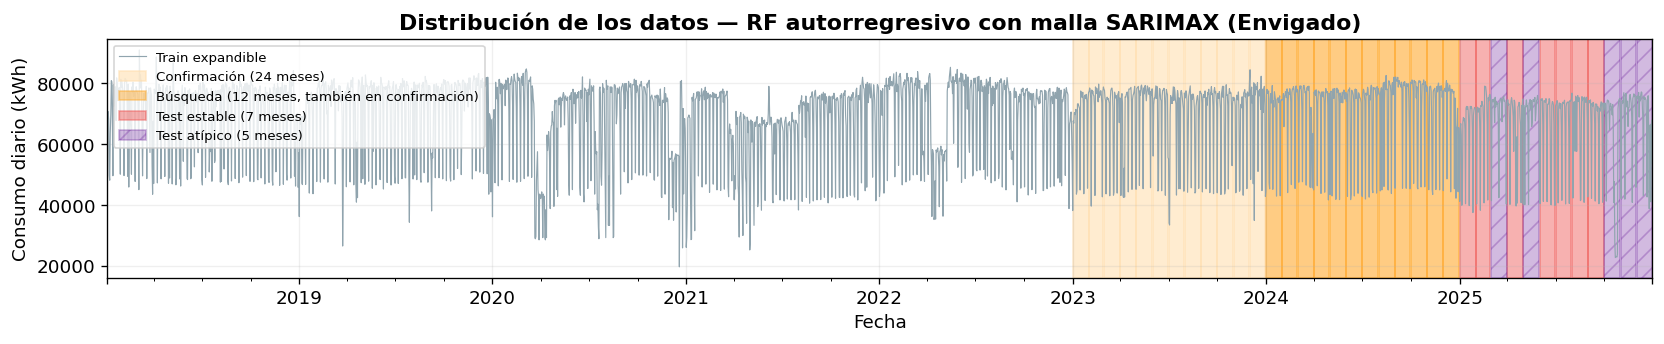

In [ ]:
fig, ax = plt.subplots(figsize=(14, 3))
df['Consumo'].plot(ax=ax, lw=0.7, color='#90A4AE', label='Train expandible')
for mes in CONFIRM_MONTHS:
    s = pd.Timestamp(f'{mes}-01'); ax.axvspan(s, s + MonthEnd(1), color='#FFE0B2', alpha=0.6)
for mes in CV_MONTHS:
    s = pd.Timestamp(f'{mes}-01'); ax.axvspan(s, s + MonthEnd(1), color='#FFA726', alpha=0.45)
ax.axvspan(0, 0, color='#FFE0B2', alpha=0.6, label=f'Confirmación ({len(CONFIRM_MONTHS)} meses)')
ax.axvspan(0, 0, color='#FFA726', alpha=0.45, label=f'Búsqueda ({len(CV_MONTHS)} meses, también en confirmación)')
for mes in STABLE_MONTHS:
    s = pd.Timestamp(f'{mes}-01'); ax.axvspan(s, s + MonthEnd(1), color='#EF5350', alpha=0.45)
ax.axvspan(0, 0, color='#EF5350', alpha=0.45, label=f'Test estable ({len(STABLE_MONTHS)} meses)')
for mes in ATYP_IN_TEST:
    s = pd.Timestamp(f'{mes}-01'); ax.axvspan(s, s + MonthEnd(1), color=COLOR_ATYPICAL, alpha=0.30, hatch='//')
ax.axvspan(0, 0, color=COLOR_ATYPICAL, alpha=0.30, hatch='//', label=f'Test atípico ({len(ATYP_IN_TEST)} meses)')
ax.set_title(f'Distribución de los datos — RF autorregresivo con malla SARIMAX ({STATION})', fontweight='bold')
ax.set_ylabel('Consumo diario (kWh)'); ax.legend(loc='upper left', fontsize=8); ax.grid(True, alpha=0.2)
plt.tight_layout(); plt.savefig(out('split_overview.png'), dpi=150, bbox_inches='tight'); plt.show()

## 6. Métricas y funciones de evaluación

| Métrica | Definición | Lectura |
|---|---|---|
| **MAPE** | media de \|e\|/y × 100 | Error porcentual promedio por día. **Criterio de selección**, igual que SARIMAX. |
| **WAPE** | Σ\|e\| / Σy × 100 | Porcentaje de la energía total del mes que se erró. |
| **MASE** | MAE / MAE del ingenuo estacional (y<sub>t</sub> − y<sub>t−7</sub>) en el train | Adimensional: comparable entre centrales. |
| MAE, RMSE | en kWh | Magnitud del error diario. |
| R² | 1 − SSE/SST dentro del mes | Variación diaria explicada. |

**Regla de simplicidad.** Cuando varios candidatos empatan estadísticamente (dentro de un error estándar del mejor), se
prefiere el más simple, en este orden: menos rezagos, menos diferenciación, hojas más grandes (`min_samples_leaf`),
árboles menos profundos (`max_depth`) y menos variables por corte (`max_features`).

In [ ]:
METRIC_COLS = ['MAE', 'RMSE', 'MAPE (%)', 'WAPE (%)', 'MASE', 'R²']

def mase_scale(cutoff, serie=None, m=SEASONAL_M):
    serie = SERIE if serie is None else serie
    y = serie.y.loc[serie.y.index < cutoff].to_numpy()
    return float(np.mean(np.abs(y[m:] - y[:-m])))

def compute_metrics(y_true, y_pred, scale=None):
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    e = y_true - y_pred
    mae  = float(np.mean(np.abs(e)))
    rmse = float(np.sqrt(np.mean(e ** 2)))
    nz   = y_true != 0
    mape = float(np.mean(np.abs(e[nz] / y_true[nz])) * 100)
    wape = float(np.sum(np.abs(e)) / np.sum(np.abs(y_true)) * 100)
    mase = mae / scale if scale else np.nan
    r2   = float(r2_score(y_true, y_pred))
    return {'MAE': round(mae, 2), 'RMSE': round(rmse, 2), 'MAPE (%)': round(mape, 4),
            'WAPE (%)': round(wape, 4), 'MASE': round(mase, 4), 'R²': round(r2, 4)}


def cv_score(params, spec, months, n_estimators=None, trial=None, metric=None, return_preds=False):
    """Walk-forward mensual con pronóstico RECURSIVO: cada fold entrena con todo lo anterior al mes y pronostica
    el mes completo. Devuelve media, std, error estándar y mediana del criterio, más todas las métricas por fold.
    Con `trial` (Optuna) reporta la media acumulada y habilita el pruning."""
    metric = metric or SELECTION_METRIC
    vals, allm, preds_out = [], [], []
    for step, mes in enumerate(months):
        cutoff = pd.Timestamp(f'{mes}-01'); dates = month_dates(mes)
        try:
            model = fit_rf(params, spec, cutoff, n_estimators=n_estimators)
            yh = forecast_recursive(model, spec, cutoff, dates)[0]
            y_true = SERIE.y.loc[dates].to_numpy()
            met = compute_metrics(y_true, yh, mase_scale(cutoff))
            if return_preds:
                preds_out.append((dates, y_true, yh))
        except Exception as ex:
            print(f"    ⚠ fold {mes}: {ex}")
            met = {k: 999.0 for k in METRIC_COLS}
        vals.append(met[metric]); allm.append(dict(met, mes=mes))
        if trial is not None:
            trial.report(float(np.mean(vals)), step)
            if trial.should_prune():
                raise optuna.TrialPruned()
    v = np.asarray(vals, float)
    sd = float(np.std(v, ddof=1)) if len(v) > 1 else 0.0
    res = {'mean': float(v.mean()), 'std': sd, 'se': sd / np.sqrt(len(v)),
           'median': float(np.median(v)), 'folds': v.tolist(), 'folds_all': allm}
    if return_preds:
        res['preds'] = preds_out
    return res


def clave_simplicidad(spec, params=None):
    """Orden de 'más simple' a 'más complejo' (ver regla de simplicidad arriba)."""
    k = [len(spec.lags), spec.d + spec.D]
    if params is not None:
        md_ = params.get('max_depth') or 10 ** 6
        k += [-params.get('min_samples_leaf', 1), md_, params.get('max_features', 1.0)]
    return tuple(k)


def permutation_groups(model, X, base, y_true, groups, n_repeats, seed=SEED):
    """Importancia por permutación sobre las entradas exactas del pronóstico recursivo.
    ŷ = predict(X) + base, con base fija tal como se usó en el pronóstico. Devuelve el aumento del MAPE (pp)."""
    rng_p = np.random.default_rng(seed)
    base_mape = compute_metrics(y_true, model.predict(X) + base)['MAPE (%)']
    res = {}
    for g, idx in groups.items():
        inc = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[:, idx] = X[rng_p.permutation(len(X))][:, idx]
            inc.append(compute_metrics(y_true, model.predict(Xp) + base)['MAPE (%)'] - base_mape)
        res[g] = float(np.mean(inc))
    return res


def build_perm_groups(spec):
    names = spec.feature_names
    g = {c: [names.index(c)] for c in names}
    g['GRUPO · calendario (11)'] = [names.index(c) for c in CAL_COLS]
    if spec.lags:
        g[f'GRUPO · rezagos ({len(spec.lags)})'] = [names.index(c) for c in spec.lag_names]
    return g

print("✓ Funciones de métricas y evaluación definidas.")

✓ Funciones de métricas y evaluación definidas.


---
# B. Verificaciones

## 7. Pruebas de consistencia, inversión de la diferenciación y no-fuga

Se ejecutan **antes** de entrenar ningún modelo de verdad, con un bosque pequeño (20 árboles), sobre dos estructuras:
la más compleja de la malla (más rezagos y doble diferenciación) y `REF_memoria70` (rezagos hasta 70 días).

| Prueba | Qué garantiza |
|---|---|
| **7.1 Consistencia** | Si a la recursión se le reinyectan los valores **reales**, construye exactamente las mismas variables que la versión vectorizada del entrenamiento. |
| **7.2 Reinyección** | `lag_1` del día *d* es la predicción ẑ del día *d−1*: el modelo usa sus propias predicciones. |
| **7.3 Inversión** | Si se diferencia la trayectoria pronosticada ŷ, se recupera exactamente ẑ: la reconstrucción del consumo es correcta. |
| **7.4 No-fuga** | Se reemplaza **todo** el consumo desde el origen en adelante por números aleatorios y se reentrena: el pronóstico debe salir **idéntico**. |
| **7.5 Control positivo** | El oráculo, que sí usa datos del mes, **debe cambiar** con la corrupción. Esto demuestra que 7.4 detecta fugas. |
| **7.6 Entradas registradas** | `predict(X_rec) + base` reproduce el pronóstico: valida la importancia por permutación. |

In [ ]:
mes_t = CV_MONTHS[0]
cut_t = pd.Timestamp(f'{mes_t}-01'); d_t = month_dates(mes_t)
spec_compleja = max(GRID, key=lambda s: (len(s.lags), s.d + s.D))
rng_t = np.random.default_rng(123)
y_corr = SERIE.y.copy()
fut = y_corr.index >= cut_t
y_corr[fut] = rng_t.uniform(0, 1e6, int(fut.sum()))
serie_corr = SerieAR(y_corr, SERIE.cal, MAX_HISTORY)

for spec_t in [spec_compleja, REF_70]:
    print(f"\n── {spec_t.name}  ({len(spec_t.feature_names)} variables, d={spec_t.d}, D={spec_t.D})  ·  mes {mes_t} ──")
    m_t = fit_rf(SKLEARN_DEFAULT_RF, spec_t, cut_t, n_estimators=20)
    y_real = SERIE.y.loc[d_t].to_numpy()

    _, X_tf, _, _ = forecast_recursive(m_t, spec_t, cut_t, d_t, feed=y_real)
    X_vec = SERIE.design(spec_t).loc[d_t].to_numpy()
    check(f'7.1 [{spec_t.name}] Recursión ≡ construcción vectorizada',
          np.allclose(X_tf, X_vec, rtol=1e-9, atol=1e-6), f"máx |dif| = {np.nanmax(np.abs(X_tf - X_vec)):.2e}")

    yh, X_r, zh, b_r = forecast_recursive(m_t, spec_t, cut_t, d_t)
    j1 = spec_t.feature_names.index('lag_1')
    check(f'7.2 [{spec_t.name}] lag_1(d) = ẑ(d−1)', np.allclose(X_r[1:, j1], zh[:-1]))

    y_path = pd.concat([SERIE.y[SERIE.y.index < cut_t], pd.Series(yh, index=d_t)])
    z_path = y_path.copy()
    for k, c in spec_t.coefs.items():
        z_path = z_path - c * y_path.shift(k)
    check(f'7.3 [{spec_t.name}] Diferenciar ŷ recupera ẑ (reconstrucción correcta)',
          np.allclose(z_path.loc[d_t].to_numpy(), zh), f"máx |dif| = {np.max(np.abs(z_path.loc[d_t].to_numpy() - zh)):.2e}")

    m_c = fit_rf(SKLEARN_DEFAULT_RF, spec_t, cut_t, serie=serie_corr, n_estimators=20)
    yh_c = forecast_recursive(m_c, spec_t, cut_t, d_t, serie=serie_corr)[0]
    check(f'7.4 [{spec_t.name}] No-fuga: pronóstico idéntico con el mes corrompido',
          np.allclose(yh, yh_c), f"máx |dif| = {np.max(np.abs(yh - yh_c)):.2e} kWh")

    or_ok = forecast_oracle(m_t, spec_t, d_t)
    or_c  = forecast_oracle(m_c, spec_t, d_t, serie=serie_corr)
    check(f'7.5 [{spec_t.name}] Control positivo: el oráculo SÍ cambia',
          not np.allclose(or_ok, or_c), f"máx |dif| = {np.max(np.abs(or_ok - or_c)):,.0f} kWh")

    check(f'7.6 [{spec_t.name}] predict(X_rec) + base reproduce el pronóstico', np.allclose(m_t.predict(X_r) + b_r, yh))
del m_t, m_c, serie_corr


── p4P2_d1D1  (25 variables, d=1, D=1)  ·  mes 2024-01 ──
✓ 7.1 [p4P2_d1D1] Recursión ≡ construcción vectorizada  —  máx |dif| = 2.18e-11
✓ 7.2 [p4P2_d1D1] lag_1(d) = ẑ(d−1)
✓ 7.3 [p4P2_d1D1] Diferenciar ŷ recupera ẑ (reconstrucción correcta)  —  máx |dif| = 2.11e-11
✓ 7.4 [p4P2_d1D1] No-fuga: pronóstico idéntico con el mes corrompido  —  máx |dif| = 0.00e+00 kWh
✓ 7.5 [p4P2_d1D1] Control positivo: el oráculo SÍ cambia  —  máx |dif| = 1,483,738 kWh
✓ 7.6 [p4P2_d1D1] predict(X_rec) + base reproduce el pronóstico

── REF_memoria70  (27 variables, d=0, D=0)  ·  mes 2024-01 ──
✓ 7.1 [REF_memoria70] Recursión ≡ construcción vectorizada  —  máx |dif| = 0.00e+00
✓ 7.2 [REF_memoria70] lag_1(d) = ẑ(d−1)
✓ 7.3 [REF_memoria70] Diferenciar ŷ recupera ẑ (reconstrucción correcta)  —  máx |dif| = 0.00e+00
✓ 7.4 [REF_memoria70] No-fuga: pronóstico idéntico con el mes corrompido  —  máx |dif| = 0.00e+00 kWh
✓ 7.5 [REF_memoria70] Control positivo: el oráculo SÍ cambia  —  máx |dif| = 21,784 kWh
✓ 7.6 [

---
# C. Selección del modelo (solo 2023–2024)

| Paso | Qué se compara | Meses | Árboles |
|---|---|---|---|
| 8. Recorrido de la malla | las 48 estructuras, con hiperparámetros por defecto de scikit-learn | 12 (2024) | `GRID_N_ESTIMATORS` |
| 9. Búsqueda principal | estructura (entre las 5 preseleccionadas) + hiperparámetros | 12 (2024) | `SEARCH_N_ESTIMATORS` |
| 10. Búsqueda de referencias | hiperparámetros de `REF_calendario` y de `REF_memoria70` | 12 (2024) | `SEARCH_N_ESTIMATORS` |
| 11. Confirmación | finalistas de cada modelo; regla de un error estándar + simplicidad | **24 (2023–2024)** | `FINAL_N_ESTIMATORS` |

## 8. Recorrido completo de la malla

Las 48 estructuras se evalúan **todas**, sin muestreo, con los mismos hiperparámetros: los valores por defecto de
scikit-learn (`max_features = 1,0`, es decir, cada corte del árbol puede elegir entre todas las variables). Así ninguna
estructura queda en desventaja por el tamaño de su conjunto de variables, que fue el problema de la versión anterior.

**Preselección para la búsqueda.** Entra siempre la mejor por MAPE medio. Después entran, hasta completar
`TOP_K_ESTRUCTURAS`, las más simples entre las que empatan con ella (dentro de un error estándar). Si no alcanzan, se
completa con las siguientes mejores.

In [ ]:
grid_rows, grid_cv = [], {}
t0 = time.time()
print(f"Recorriendo {len(GRID)} estructuras × {len(CV_MONTHS)} meses con {GRID_N_ESTIMATORS} árboles…")
for i, spec in enumerate(GRID):
    cvs = cv_score(SKLEARN_DEFAULT_RF, spec, CV_MONTHS, n_estimators=GRID_N_ESTIMATORS)
    grid_cv[spec.name] = cvs
    fm = pd.DataFrame(cvs['folds_all'])
    grid_rows.append({'estructura': spec.name, 'p': spec.p, 'P': spec.P, 'd': spec.d, 'D': spec.D,
                      'n_rezagos': len(spec.lags), 'criterio_media': cvs['mean'], 'criterio_se': cvs['se'],
                      'criterio_mediana': cvs['median'], 'MAPE (%)': fm['MAPE (%)'].mean(),
                      'WAPE (%)': fm['WAPE (%)'].mean(), 'MASE': fm['MASE'].mean(), 'MAE': fm['MAE'].mean()})
    print(f"  [{i+1:>2}/{len(GRID)}] {spec.name:<12} rezagos={len(spec.lags):>2}  "
          f"{SELECTION_METRIC}={cvs['mean']:.3f} ± {cvs['se']:.3f}   t={(time.time()-t0)/60:.1f} min")

grid_df = pd.DataFrame(grid_rows).sort_values('criterio_media').reset_index(drop=True)
best = grid_df.iloc[0]
umbral_grid = best['criterio_media'] + best['criterio_se']
empatadas = grid_df[grid_df['criterio_media'] <= umbral_grid].copy()
empatadas['_k'] = [clave_simplicidad(SPEC_BY_NAME[e]) for e in empatadas['estructura']]
SHORTLIST = [best['estructura']]
for e in empatadas.sort_values('_k')['estructura']:
    if len(SHORTLIST) >= TOP_K_ESTRUCTURAS: break
    if e not in SHORTLIST: SHORTLIST.append(e)
for e in grid_df['estructura']:
    if len(SHORTLIST) >= TOP_K_ESTRUCTURAS: break
    if e not in SHORTLIST: SHORTLIST.append(e)
grid_df['preseleccionada'] = grid_df['estructura'].isin(SHORTLIST)
grid_df['elegida'] = False
TIEMPOS['8. Malla completa'] = (time.time() - t0) / 60

print(f"\nMejor estructura         : {best['estructura']}   ({best['criterio_media']:.3f})")
print(f"Umbral (mejor + 1 SE)    : {umbral_grid:.3f}  →  {len(empatadas)} estructuras empatadas")
print(f"Preseleccionadas         : {SHORTLIST}")
print("\nTop 15:")
print(grid_df.head(15).round(3).to_string(index=False))
grid_df.to_csv(out('malla_estructuras_cv.csv'), index=False)

Recorriendo 48 estructuras × 12 meses con 100 árboles…
  [ 1/48] p1P0_d0D0    rezagos= 1  MAPE (%)=4.124 ± 0.409   t=0.5 min
  [ 2/48] p1P0_d0D1    rezagos= 1  MAPE (%)=15.947 ± 2.869   t=0.9 min
  [ 3/48] p1P0_d1D0    rezagos= 1  MAPE (%)=9.982 ± 1.707   t=1.2 min
  [ 4/48] p1P0_d1D1    rezagos= 1  MAPE (%)=36.367 ± 8.176   t=1.5 min
  [ 5/48] p2P0_d0D0    rezagos= 2  MAPE (%)=4.250 ± 0.398   t=1.9 min
  [ 6/48] p2P0_d0D1    rezagos= 2  MAPE (%)=19.410 ± 3.937   t=2.3 min
  [ 7/48] p2P0_d1D0    rezagos= 2  MAPE (%)=6.560 ± 0.912   t=2.7 min
  [ 8/48] p2P0_d1D1    rezagos= 2  MAPE (%)=40.461 ± 6.422   t=3.1 min
  [ 9/48] p1P1_d0D0    rezagos= 3  MAPE (%)=4.004 ± 0.341   t=3.6 min
  [10/48] p3P0_d0D0    rezagos= 3  MAPE (%)=4.347 ± 0.291   t=4.0 min
  [11/48] p1P1_d0D1    rezagos= 3  MAPE (%)=6.955 ± 1.543   t=4.5 min
  [12/48] p1P1_d1D0    rezagos= 3  MAPE (%)=9.467 ± 1.924   t=5.0 min
  [13/48] p3P0_d0D1    rezagos= 3  MAPE (%)=14.679 ± 3.182   t=5.5 min
  [14/48] p3P0_d1D0    rezagos

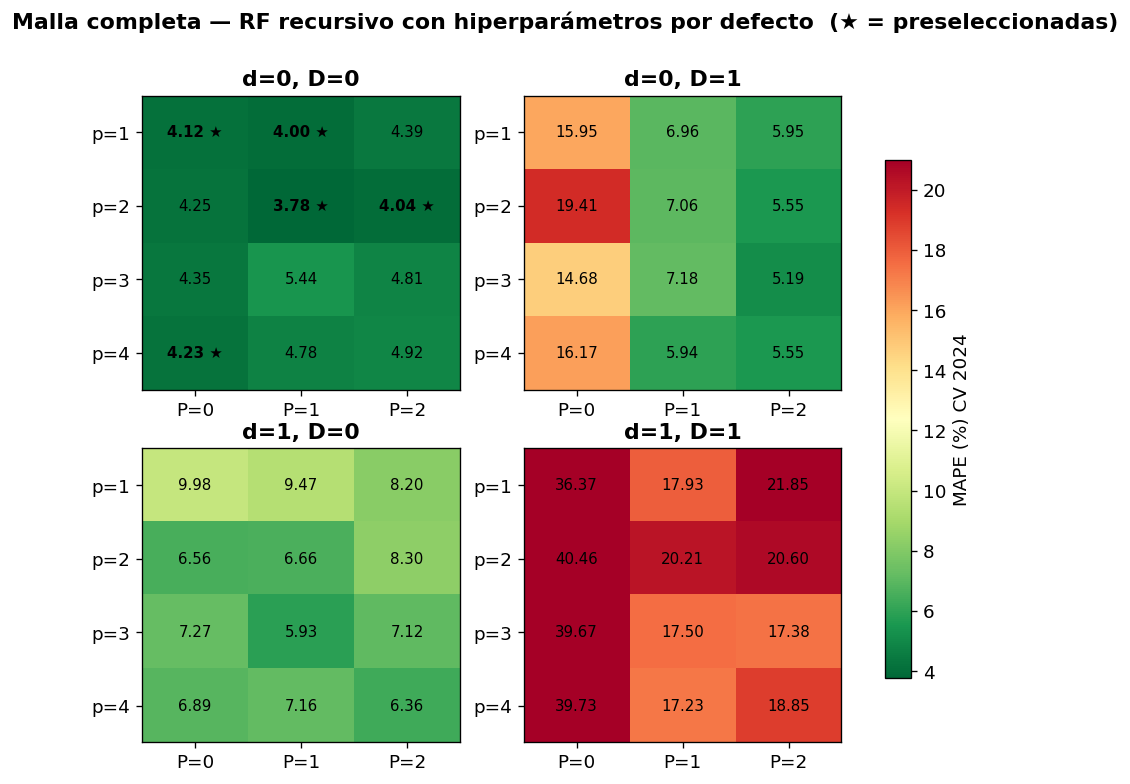

Efecto promedio de cada orden (media del criterio sobre las estructuras con ese valor):
  p: 1→12.098  2→12.241  3→11.378  4→11.485
  P: 0→16.882  1→9.202  2→9.317
  d: 0→7.029  1→16.571
  D: 0→5.960  1→17.641


In [ ]:
# Mapa de la malla: un panel por combinación de diferenciación (d, D); dentro, p (filas) × P (columnas)
vmin, vmax = grid_df['criterio_media'].min(), grid_df['criterio_media'].quantile(0.9)
fig, axes = plt.subplots(len(D_REG), len(D_SEAS), figsize=(4.2 * len(D_SEAS) + 1, 3.2 * len(D_REG) + 0.6),
                         squeeze=False)
for a, d_ in enumerate(D_REG):
    for b, D_ in enumerate(D_SEAS):
        ax = axes[a][b]
        sub = grid_df[(grid_df['d'] == d_) & (grid_df['D'] == D_)]
        mat = sub.pivot(index='p', columns='P', values='criterio_media').reindex(index=P_AR, columns=P_SAR)
        im = ax.imshow(mat.values, cmap='RdYlGn_r', vmin=vmin, vmax=vmax, aspect='auto')
        for i_, p_ in enumerate(P_AR):
            for j_, P_ in enumerate(P_SAR):
                v = mat.loc[p_, P_]
                nm = f'p{p_}P{P_}_d{d_}D{D_}'
                ax.text(j_, i_, f"{v:.2f}" + (' ★' if nm in SHORTLIST else ''), ha='center', va='center',
                        fontsize=9, fontweight='bold' if nm in SHORTLIST else 'normal')
        ax.set_xticks(range(len(P_SAR))); ax.set_xticklabels([f'P={x}' for x in P_SAR])
        ax.set_yticks(range(len(P_AR))); ax.set_yticklabels([f'p={x}' for x in P_AR])
        ax.set_title(f'd={d_}, D={D_}', fontweight='bold')
fig.colorbar(im, ax=axes, shrink=0.8, label=f'{SELECTION_METRIC} CV 2024')
fig.suptitle('Malla completa — RF recursivo con hiperparámetros por defecto  (★ = preseleccionadas)', fontweight='bold')
plt.savefig(out('malla_estructuras_cv.png'), dpi=150, bbox_inches='tight'); plt.show()

print("Efecto promedio de cada orden (media del criterio sobre las estructuras con ese valor):")
for col in ['p', 'P', 'd', 'D']:
    print(f"  {col}: " + "  ".join(f"{k}→{v:.3f}" for k, v in grid_df.groupby(col)['criterio_media'].mean().items()))

## 9. Búsqueda conjunta principal

En cada trial, Optuna (TPE multivariado) elige **una estructura preseleccionada y una combinación de hiperparámetros**, y
la evalúa con el walk-forward recursivo de 2024.

| Hiperparámetro | Rango |
|---|---|
| `estructura` | las `TOP_K_ESTRUCTURAS` preseleccionadas en la sección 8 |
| `max_depth` | sin límite, 10, 15, 20 o 30 |
| `min_samples_leaf` | 1 a 10 (escala logarítmica) |
| `max_features` | 0,2 a 1,0 (fracción de variables por corte) |
| `max_samples` | 0,5 a 1,0 (fracción de filas por árbol) |

Arranca desde cero, con trials aleatorios iniciales. El pruning corta, después de 4 meses, las combinaciones que van peor
que la mediana. Se detiene en `N_TRIALS` o `TIEMPO_BUSQUEDA_MIN`.

El puntaje de esta búsqueda es **optimista**, porque se elige el mejor de muchos sobre los mismos 12 meses. Por eso la
decisión final se toma en la confirmación de 24 meses (sección 11).

In [ ]:
MAX_DEPTH_OPC = [0, 10, 15, 20, 30]          # 0 → None (sin límite)
PARAM_KEYS = ('max_depth', 'min_samples_leaf', 'max_features', 'max_samples')

def _sugerir_params(trial):
    md_ = trial.suggest_categorical('max_depth', MAX_DEPTH_OPC)
    return dict(max_depth=None if md_ == 0 else int(md_),
                min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 10, log=True),
                max_features=round(trial.suggest_float('max_features', 0.2, 1.0), 3),
                max_samples=round(trial.suggest_float('max_samples', 0.5, 1.0), 3))

def _last_value(t):
    if t.value is not None:
        return t.value
    iv = t.intermediate_values
    return iv[max(iv)] if iv else None

def run_search(etiqueta, estructuras, n_trials, tiempo_min, n_startup):
    """Búsqueda de estructura (entre `estructuras`) + hiperparámetros. Devuelve (tabla, info por trial, study)."""
    info, rows = {}, []
    t0 = time.time()
    study = None
    if HAS_OPTUNA:
        def objective(trial):
            est = trial.suggest_categorical('estructura', list(estructuras))
            params = _sugerir_params(trial)
            info[trial.number + 1] = (est, params)
            cvs = cv_score(params, SPEC_BY_NAME[est], CV_MONTHS, n_estimators=SEARCH_N_ESTIMATORS, trial=trial)
            trial.set_user_attr('cv_std', cvs['std']); trial.set_user_attr('cv_se', cvs['se'])
            trial.set_user_attr('cv_median', cvs['median'])
            return cvs['mean']

        def _registrar(study, t):
            num = t.number + 1
            est, params = info.get(num, (t.params.get('estructura'), {}))
            v = _last_value(t); podado = t.state == optuna.trial.TrialState.PRUNED
            rows.append({'trial': num, 'estructura': est, 'cv_score': v,
                         'cv_std': t.user_attrs.get('cv_std'), 'cv_se': t.user_attrs.get('cv_se'),
                         'cv_median': t.user_attrs.get('cv_median'), 'pruned': podado,
                         **{k: params.get(k) for k in PARAM_KEYS}})
            completos = [x for x in study.trials if x.state == optuna.trial.TrialState.COMPLETE]
            mejor = study.best_value if completos else float('nan')
            print(f"  [{etiqueta}] trial {num:>3}  {str(est):<16} {SELECTION_METRIC}="
                  f"{'—' if v is None else f'{v:.3f}'}{' (cortado)' if podado else ''}   "
                  f"mejor={mejor:.3f}   t={(time.time()-t0)/60:.1f} min")

        study = optuna.create_study(
            direction='minimize',
            sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=n_startup, multivariate=True),
            pruner=optuna.pruners.MedianPruner(n_startup_trials=n_startup, n_warmup_steps=3))
        study.optimize(objective, n_trials=n_trials, timeout=tiempo_min * 60,
                       catch=(Exception,), callbacks=[_registrar])
    else:
        rng_s = np.random.default_rng(SEED)
        for it in range(n_trials):
            if time.time() - t0 > tiempo_min * 60:
                break
            est = str(rng_s.choice(list(estructuras))); md_ = int(rng_s.choice(MAX_DEPTH_OPC))
            params = dict(max_depth=None if md_ == 0 else md_,
                          min_samples_leaf=int(np.round(np.exp(rng_s.uniform(0, np.log(10))))),
                          max_features=round(float(rng_s.uniform(0.2, 1.0)), 3),
                          max_samples=round(float(rng_s.uniform(0.5, 1.0)), 3))
            info[it + 1] = (est, params)
            cvs = cv_score(params, SPEC_BY_NAME[est], CV_MONTHS, n_estimators=SEARCH_N_ESTIMATORS)
            rows.append({'trial': it + 1, 'estructura': est, 'cv_score': cvs['mean'], 'cv_std': cvs['std'],
                         'cv_se': cvs['se'], 'cv_median': cvs['median'], 'pruned': False,
                         **{k: params[k] for k in PARAM_KEYS}})
            print(f"  [{etiqueta}] trial {it+1:>3}  {est:<16} {SELECTION_METRIC}={cvs['mean']:.3f}")
    tabla = pd.DataFrame(rows).sort_values('trial').reset_index(drop=True)
    return tabla, info, study

t0 = time.time()
tuning_main, INFO_MAIN, study_main = run_search('principal', SHORTLIST, N_TRIALS, TIEMPO_BUSQUEDA_MIN,
                                                n_startup=min(10, max(2, N_TRIALS // 4)))
TIEMPOS['9. Búsqueda principal'] = (time.time() - t0) / 60
tuning_main.to_csv(out('tuning_principal.csv'), index=False)
comp_main = tuning_main[(~tuning_main['pruned']) & tuning_main['cv_score'].notna()]
print(f"\nBúsqueda principal: {len(tuning_main)} trials ({len(comp_main)} completos) en {TIEMPOS['9. Búsqueda principal']:.1f} min")
check('Búsqueda principal con suficientes trials completos', len(comp_main) >= N_FINALISTAS,
      f"{len(comp_main)} completos, se necesitan {N_FINALISTAS}")

  [principal] trial   1  p1P1_d0D0        MAPE (%)=4.011   mejor=4.011   t=0.7 min
  [principal] trial   2  p4P0_d0D0        MAPE (%)=4.015   mejor=4.011   t=1.1 min
  [principal] trial   3  p4P0_d0D0        MAPE (%)=4.240   mejor=4.011   t=1.5 min
  [principal] trial   4  p4P0_d0D0        MAPE (%)=5.087   mejor=4.011   t=2.1 min
  [principal] trial   5  p2P1_d0D0        MAPE (%)=4.494   mejor=4.011   t=2.5 min
  [principal] trial   6  p4P0_d0D0        MAPE (%)=4.990   mejor=4.011   t=2.9 min
  [principal] trial   7  p2P2_d0D0        MAPE (%)=4.468   mejor=4.011   t=3.3 min
  [principal] trial   8  p1P0_d0D0        MAPE (%)=4.108   mejor=4.011   t=3.6 min
  [principal] trial   9  p2P1_d0D0        MAPE (%)=3.835   mejor=3.835   t=4.3 min
  [principal] trial  10  p4P0_d0D0        MAPE (%)=6.418   mejor=3.835   t=4.6 min
  [principal] trial  11  p2P1_d0D0        MAPE (%)=3.861   mejor=3.835   t=5.4 min
  [principal] trial  12  p2P1_d0D0        MAPE (%)=3.777   mejor=3.777   t=6.0 min
  [p

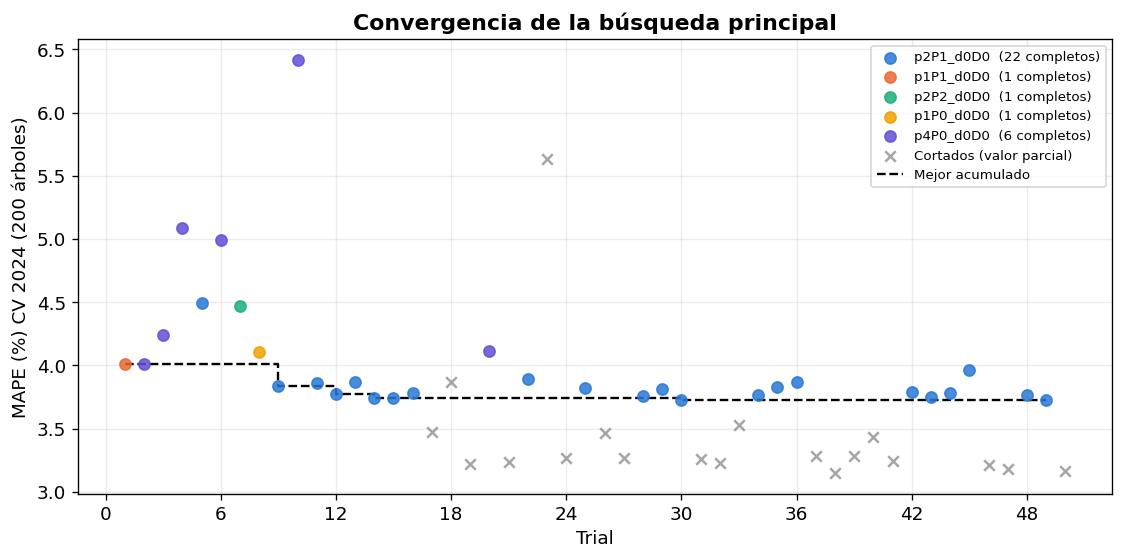

Resumen por estructura (trials completos):
            count    min  median
estructura                      
p1P0_d0D0       1  4.108   4.108
p1P1_d0D0       1  4.011   4.011
p2P1_d0D0      22  3.725   3.784
p2P2_d0D0       1  4.468   4.468
p4P0_d0D0       6  4.015   4.615

Importancia de cada hiperparámetro en la búsqueda (fANOVA, suma 1):
  max_features       0.29
  estructura         0.23
  max_samples        0.22
  min_samples_leaf   0.16
  max_depth          0.10


In [ ]:
SCOL_EST = {e: CAT[i % len(CAT)] for i, e in enumerate(SHORTLIST)}
prun = tuning_main[tuning_main['pruned'] & tuning_main['cv_score'].notna()]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for e in SHORTLIST:
    c = comp_main[comp_main['estructura'] == e]
    ax.scatter(c['trial'], c['cv_score'], color=SCOL_EST[e], s=45, alpha=0.85, zorder=3, label=f'{e}  ({len(c)} completos)')
if len(prun):
    ax.scatter(prun['trial'], prun['cv_score'], marker='x', color='gray', s=40, alpha=0.7, zorder=2, label='Cortados (valor parcial)')
bsf = comp_main.set_index('trial')['cv_score'].cummin()
ax.step(bsf.index, bsf.values, where='post', color='black', ls='--', lw=1.4, label='Mejor acumulado')
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.set_xlabel('Trial'); ax.set_ylabel(f'{SELECTION_METRIC} CV 2024 ({SEARCH_N_ESTIMATORS} árboles)')
ax.set_title('Convergencia de la búsqueda principal', fontweight='bold')
ax.legend(fontsize=8); ax.grid(True, alpha=0.25)
plt.tight_layout(); plt.savefig(out('tuning_convergencia_principal.png'), dpi=150, bbox_inches='tight'); plt.show()

print("Resumen por estructura (trials completos):")
print(comp_main.groupby('estructura')['cv_score'].agg(['count', 'min', 'median']).round(3).to_string())
if HAS_OPTUNA and len(comp_main) >= 5:
    try:
        imp = optuna.importance.get_param_importances(study_main)
        print("\nImportancia de cada hiperparámetro en la búsqueda (fANOVA, suma 1):")
        for k, v in imp.items():
            print(f"  {k:<18} {v:.2f}")
    except Exception as ex:
        print(f"(No se pudo calcular la importancia de hiperparámetros: {ex})")

## 10. Búsqueda de hiperparámetros de las referencias

Cada referencia tiene su propia búsqueda, con la estructura fija y los mismos rangos de hiperparámetros: hasta
`N_TRIALS_REF` trials o `TIEMPO_REF_MIN` minutos. Así la comparación entre el modelo principal y las referencias es entre
versiones tuneadas, no contra hiperparámetros elegidos para otra estructura.

In [ ]:
REF_SEARCH = {}
for spec in REFS:
    t0 = time.time()
    tab, info, st = run_search(spec.name, [spec.name], N_TRIALS_REF, TIEMPO_REF_MIN,
                               n_startup=min(5, max(2, N_TRIALS_REF // 3)))
    comp = tab[(~tab['pruned']) & tab['cv_score'].notna()]
    REF_SEARCH[spec.name] = {'tabla': tab, 'info': info, 'study': st, 'comp': comp}
    TIEMPOS[f'10. Búsqueda {spec.name}'] = (time.time() - t0) / 60
    tab.to_csv(out(f'tuning_{spec.name}.csv'), index=False)
    print(f"→ {spec.name}: {len(tab)} trials ({len(comp)} completos), mejor {SELECTION_METRIC} = "
          f"{comp['cv_score'].min():.3f}, en {TIEMPOS[f'10. Búsqueda {spec.name}']:.1f} min\n")
    check(f'Búsqueda {spec.name} con suficientes trials completos', len(comp) >= N_FINALISTAS_REF,
          f"{len(comp)} completos, se necesitan {N_FINALISTAS_REF}")

  [REF_calendario] trial   1  REF_calendario   MAPE (%)=4.790   mejor=4.790   t=0.1 min
  [REF_calendario] trial   2  REF_calendario   MAPE (%)=4.210   mejor=4.210   t=0.2 min
  [REF_calendario] trial   3  REF_calendario   MAPE (%)=4.085   mejor=4.085   t=0.4 min
  [REF_calendario] trial   4  REF_calendario   MAPE (%)=4.095   mejor=4.085   t=0.5 min
  [REF_calendario] trial   5  REF_calendario   MAPE (%)=4.075   mejor=4.075   t=0.7 min
  [REF_calendario] trial   6  REF_calendario   MAPE (%)=3.925   mejor=3.925   t=0.8 min
  [REF_calendario] trial   7  REF_calendario   MAPE (%)=4.024   mejor=3.925   t=0.9 min
  [REF_calendario] trial   8  REF_calendario   MAPE (%)=3.907 (cortado)   mejor=3.925   t=0.9 min
  [REF_calendario] trial   9  REF_calendario   MAPE (%)=3.953   mejor=3.925   t=1.1 min
  [REF_calendario] trial  10  REF_calendario   MAPE (%)=3.851   mejor=3.851   t=1.2 min
  [REF_calendario] trial  11  REF_calendario   MAPE (%)=3.789   mejor=3.789   t=1.4 min
  [REF_calendario] tri

## 11. Confirmación en 24 meses (2023–2024)

Esta etapa reduce el sobreajuste al año de búsqueda. Para cada modelo (principal y las dos referencias):

1. **Finalistas.** Entre todos los trials completos se identifican los que empatan con el mejor (dentro de un error
   estándar de su puntaje de búsqueda). Pasan a la confirmación el mejor por puntaje y los más simples entre los empatados,
   hasta `N_FINALISTAS` (referencias: `N_FINALISTAS_REF`).
2. **Reevaluación.** Cada finalista se evalúa con `FINAL_N_ESTIMATORS` árboles en los **24 meses** de 2023–2024. Un
   candidato que ganó en 2024 por azar difícilmente repite en 2023.
3. **Elección.** Se toma el mejor promedio de 24 meses, se le suma su error estándar, y entre los que quedan por debajo se
   elige el **más simple**.

Las predicciones recursivas fuera de muestra del ganador principal en estos 24 meses se reutilizan para calibrar las
bandas de la sección 24.

In [ ]:
def finalistas(comp, info, n):
    comp = comp.sort_values('cv_score')
    mejor = comp.iloc[0]
    se = mejor['cv_se'] if pd.notna(mejor['cv_se']) else 0.0
    umbral = mejor['cv_score'] + se
    emp = comp[comp['cv_score'] <= umbral]
    orden = sorted(emp['trial'], key=lambda t: clave_simplicidad(SPEC_BY_NAME[info[t][0]], info[t][1]))
    elegidos = [int(mejor['trial'])]
    for t in list(orden) + list(comp['trial']):
        if len(elegidos) >= n: break
        if int(t) not in elegidos: elegidos.append(int(t))
    return elegidos, umbral, len(emp)

def confirmar(nombre, comp, info, n):
    elegidos, umbral_b, n_emp = finalistas(comp, info, n)
    print(f"── {nombre}: {n_emp} trials empatados en la búsqueda (umbral {umbral_b:.3f}); finalistas {elegidos}")
    rows, cvs_by = [], {}
    for num in elegidos:
        est, params = info[num]; spec = SPEC_BY_NAME[est]
        cvs = cv_score(params, spec, CONFIRM_MONTHS, n_estimators=FINAL_N_ESTIMATORS, return_preds=True)
        cvs_by[num] = cvs
        busq = float(comp.loc[comp['trial'] == num, 'cv_score'].iloc[0])
        cv24 = cvs['folds'][-len(CV_MONTHS):]
        rows.append({'modelo': nombre, 'trial': num, 'estructura': est, 'n_rezagos': len(spec.lags),
                     'cv_busqueda_2024': busq, 'cv24_media': cvs['mean'], 'cv24_se': cvs['se'],
                     'cv24_solo_2024': float(np.mean(cv24)), **params})
        print(f"   trial {num:>3}  {est:<16} búsqueda={busq:.3f}  →  24 meses={cvs['mean']:.3f} ± {cvs['se']:.3f}")
    cdf = pd.DataFrame(rows)
    i_b = int(cdf['cv24_media'].idxmin())
    umbral = cdf.loc[i_b, 'cv24_media'] + cdf.loc[i_b, 'cv24_se']
    cand = cdf[cdf['cv24_media'] <= umbral]
    num_g = sorted(cand['trial'], key=lambda t: clave_simplicidad(SPEC_BY_NAME[info[t][0]], info[t][1]))[0]
    cdf['elegido'] = cdf['trial'] == num_g
    est, params = info[num_g]
    print(f"   umbral 24 meses = {umbral:.3f}  →  elegido trial {num_g} ({est})\n")
    return {'conf_df': cdf, 'trial': num_g, 'spec': SPEC_BY_NAME[est], 'params': dict(params, n_estimators=FINAL_N_ESTIMATORS),
            'stats': {k: cvs_by[num_g][k] for k in ('mean', 'std', 'se', 'median')}, 'preds': cvs_by[num_g]['preds']}

t0 = time.time()
CONF_MAIN = confirmar('RF malla SARIMAX', comp_main, INFO_MAIN, N_FINALISTAS)
CONF_REF = {s.name: confirmar(s.name, REF_SEARCH[s.name]['comp'], REF_SEARCH[s.name]['info'], N_FINALISTAS_REF)
            for s in REFS}
TIEMPOS['11. Confirmación 24 meses'] = (time.time() - t0) / 60

SPEC = CONF_MAIN['spec']
best_params_rf = CONF_MAIN['params']
best_stats = CONF_MAIN['stats']
CAL_PREDS = CONF_MAIN['preds']
grid_df['elegida'] = grid_df['estructura'] == SPEC.name
grid_df.to_csv(out('malla_estructuras_cv.csv'), index=False)

MODELOS = {   # clave → (etiqueta, spec, params)
    'rf_malla':      ('RF malla SARIMAX', SPEC, best_params_rf),
    'rf_calendario': ('RF solo calendario', CONF_REF['REF_calendario']['spec'], CONF_REF['REF_calendario']['params']),
    'rf_memoria70':  ('RF memoria 70 días', CONF_REF['REF_memoria70']['spec'], CONF_REF['REF_memoria70']['params']),
}
conf_all = pd.concat([CONF_MAIN['conf_df']] + [CONF_REF[s.name]['conf_df'] for s in REFS], ignore_index=True)
conf_all.to_csv(out('confirmacion_24_meses.csv'), index=False)

print("=" * 78)
print(f"{'Modelo':<22}{'Estructura':<16}{'Búsqueda 2024':>15}{'24 meses':>12}   Hiperparámetros")
for key, (lab, spec, params) in MODELOS.items():
    cd = (CONF_MAIN if key == 'rf_malla' else CONF_REF[spec.name])
    row = cd['conf_df'][cd['conf_df']['elegido']].iloc[0]
    print(f"{lab:<22}{spec.name:<16}{row['cv_busqueda_2024']:>15.3f}{row['cv24_media']:>12.3f}   "
          f"{ {k: params[k] for k in PARAM_KEYS} }")
print("=" * 78)
print(f"Modelo principal: {SPEC.name} — {SPEC.descripcion}")
print(f"Default (scikit-learn) para el contraste: {DEFAULT_RF}")

── RF malla SARIMAX: 20 trials empatados en la búsqueda (umbral 3.927); finalistas [49, 13, 44]
   trial  49  p2P1_d0D0        búsqueda=3.725  →  24 meses=4.087 ± 0.281
   trial  13  p2P1_d0D0        búsqueda=3.870  →  24 meses=4.353 ± 0.305
   trial  44  p2P1_d0D0        búsqueda=3.778  →  24 meses=4.281 ± 0.305
   umbral 24 meses = 4.368  →  elegido trial 13 (p2P1_d0D0)

── REF_calendario: 11 trials empatados en la búsqueda (umbral 4.156); finalistas [11, 15]
   trial  11  REF_calendario   búsqueda=3.789  →  24 meses=4.599 ± 0.429
   trial  15  REF_calendario   búsqueda=3.866  →  24 meses=4.436 ± 0.375
   umbral 24 meses = 4.811  →  elegido trial 15 (REF_calendario)

── REF_memoria70: 9 trials empatados en la búsqueda (umbral 4.154); finalistas [15, 6]
   trial  15  REF_memoria70    búsqueda=3.879  →  24 meses=4.403 ± 0.379
   trial   6  REF_memoria70    búsqueda=3.985  →  24 meses=4.476 ± 0.389
   umbral 24 meses = 4.782  →  elegido trial 6 (REF_memoria70)

Modelo                Est

---
# D. Evaluación en test 2025

## 12. Evaluación final

Para cada mes de 2025 se entrena con **todo lo anterior a ese mes** y se pronostica el mes completo de forma recursiva.
Estructuras e hiperparámetros quedan fijos desde la parte C. Se evalúan:

- **default**: la estructura elegida con los hiperparámetros por defecto de scikit-learn;
- **tuned**: el modelo principal (estructura e hiperparámetros elegidos);
- las **dos referencias tuneadas**, el **oráculo** (diagnóstico) y el **ingenuo estacional** (sección 21).

Para el modelo principal también se guardan la importancia MDI y la importancia por permutación (meses estables). Los
modelos se descartan después de cada mes para no acumular memoria.

In [ ]:
PERM_GROUPS = build_perm_groups(SPEC)
results = {}
t0 = time.time()
for mes in TEST_MONTHS:
    cutoff = pd.Timestamp(f'{mes}-01'); dates = month_dates(mes)
    y_true = SERIE.y.loc[dates].to_numpy(); scale = mase_scale(cutoff)
    results[mes] = {}
    for variant, params in [('default', DEFAULT_RF), ('tuned', best_params_rf)]:
        model = fit_rf(params, SPEC, cutoff)
        yh, X_rec, zh, b_rec = forecast_recursive(model, SPEC, cutoff, dates)
        r = {'dates': dates, 'real': y_true, 'preds': yh, 'scale': scale,
             'metrics': compute_metrics(y_true, yh, scale)}
        if variant == 'tuned':
            r['modelos'] = {'rf_malla': yh,
                            'oraculo': forecast_oracle(model, SPEC, dates),
                            'naive': forecast_seasonal_naive(cutoff, dates)}
            r['mdi'] = pd.Series(model.feature_importances_, index=SPEC.feature_names)
            if mes in STABLE_MONTHS:
                r['perm'] = permutation_groups(model, X_rec, b_rec, y_true, PERM_GROUPS, N_PERM_REPEATS)
        results[mes][variant] = r
        del model
    for key in ('rf_calendario', 'rf_memoria70'):
        _, spec_r, params_r = MODELOS[key]
        m_r = fit_rf(params_r, spec_r, cutoff)
        results[mes]['tuned']['modelos'][key] = forecast_recursive(m_r, spec_r, cutoff, dates)[0]
        del m_r
    mm = results[mes]['tuned']['modelos']
    print(f"  ✓ {mes}  MAPE default={results[mes]['default']['metrics']['MAPE (%)']:.2f}%  "
          f"tuned={results[mes]['tuned']['metrics']['MAPE (%)']:.2f}%  "
          f"calendario={compute_metrics(y_true, mm['rf_calendario'])['MAPE (%)']:.2f}%  "
          f"memoria70={compute_metrics(y_true, mm['rf_memoria70'])['MAPE (%)']:.2f}%   t={(time.time()-t0)/60:.1f} min")
TIEMPOS['12. Evaluación en test'] = (time.time() - t0) / 60
print(f"\n✓ Evaluación completa ({TIEMPOS['12. Evaluación en test']:.1f} min).")

  ✓ 2025-01  MAPE default=6.26%  tuned=6.63%  calendario=10.18%  memoria70=7.51%   t=0.7 min
  ✓ 2025-02  MAPE default=3.68%  tuned=4.76%  calendario=6.18%  memoria70=4.75%   t=1.3 min
  ✓ 2025-03  MAPE default=6.51%  tuned=7.93%  calendario=6.45%  memoria70=6.85%   t=1.9 min
  ✓ 2025-04  MAPE default=7.06%  tuned=6.11%  calendario=4.12%  memoria70=5.46%   t=2.5 min
  ✓ 2025-05  MAPE default=5.08%  tuned=5.42%  calendario=5.05%  memoria70=4.49%   t=3.1 min
  ✓ 2025-06  MAPE default=7.10%  tuned=6.80%  calendario=7.63%  memoria70=6.36%   t=3.8 min
  ✓ 2025-07  MAPE default=2.07%  tuned=3.47%  calendario=3.21%  memoria70=3.79%   t=4.5 min
  ✓ 2025-08  MAPE default=3.54%  tuned=4.05%  calendario=4.60%  memoria70=4.65%   t=5.2 min
  ✓ 2025-09  MAPE default=3.38%  tuned=3.69%  calendario=4.82%  memoria70=4.60%   t=5.8 min
  ✓ 2025-10  MAPE default=31.14%  tuned=32.91%  calendario=30.14%  memoria70=34.56%   t=6.5 min
  ✓ 2025-11  MAPE default=6.83%  tuned=6.45%  calendario=6.24%  memoria70=6

## 13. Predicción vs Real — Default vs Tuneado

Los meses atípicos van marcados con **⚠** y **no entran** en los promedios.

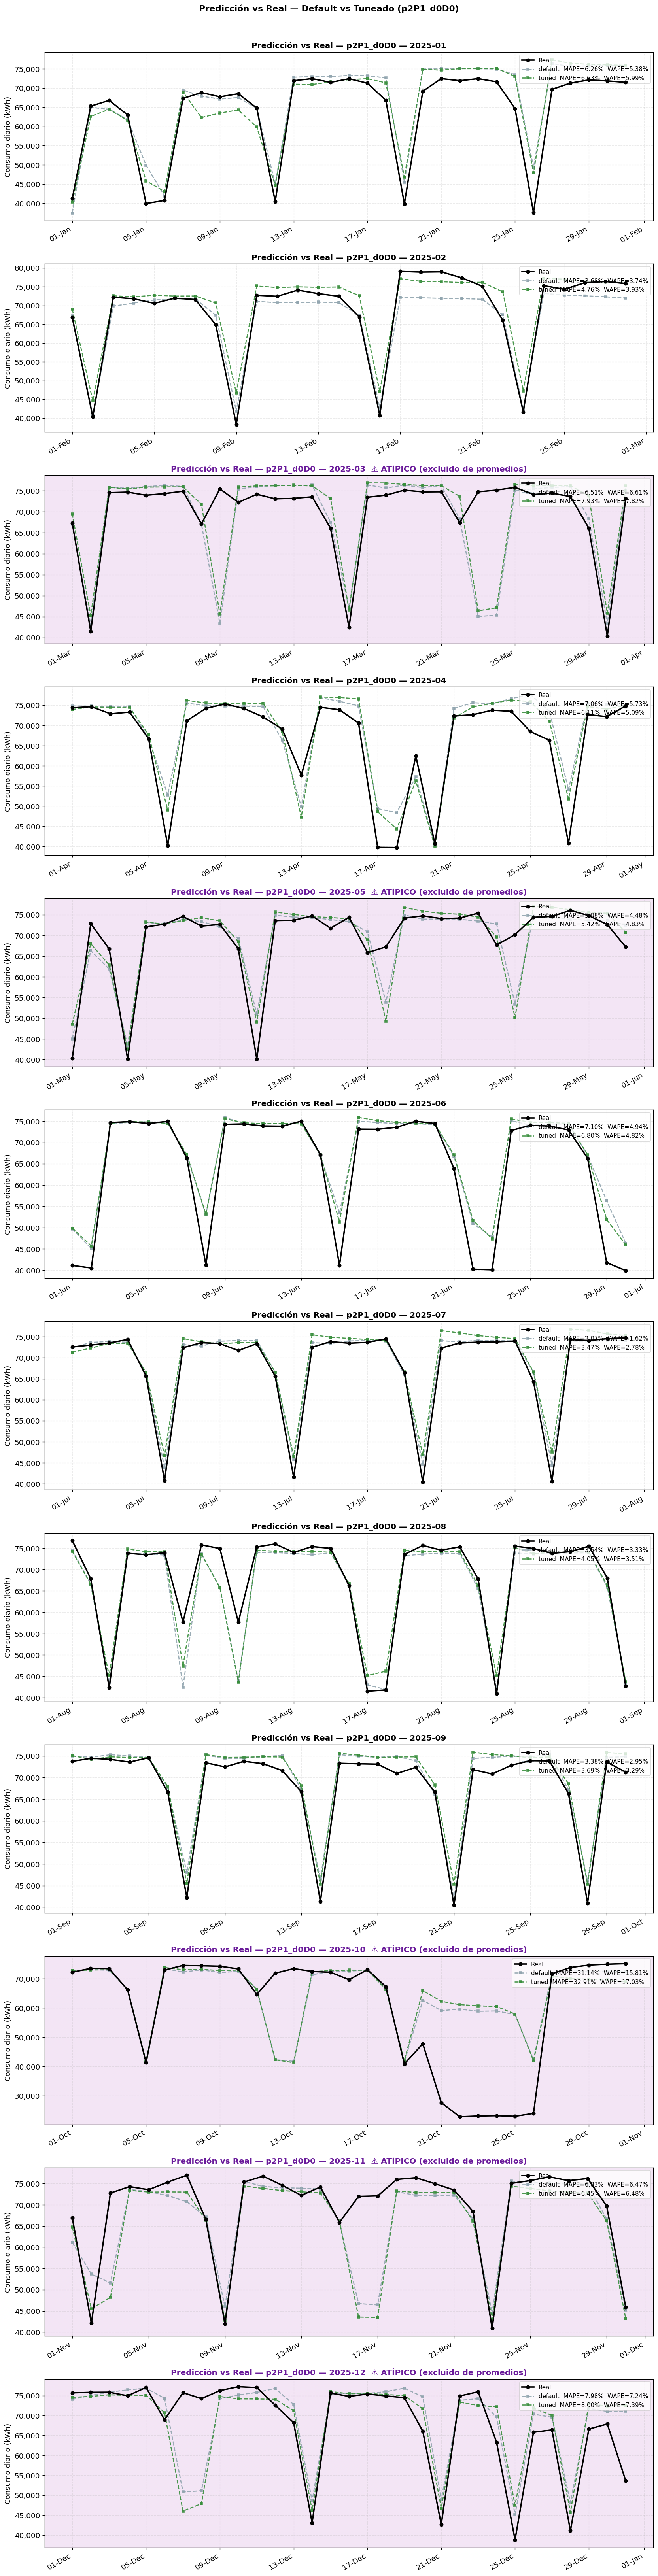

In [ ]:
n = len(PLOT_MONTHS)
fig, axes = plt.subplots(n, 1, figsize=(14, 4.5 * n), sharex=False)
axes = np.atleast_1d(axes)
for ax, mes in zip(axes, PLOT_MONTHS):
    dates = results[mes]['tuned']['dates']
    ax.plot(dates, results[mes]['tuned']['real'], 'k-o', lw=2.2, ms=5, label='Real', zorder=6)
    for variant in VARIANTS:
        r = results[mes][variant]
        ax.plot(dates, r['preds'], '--s', ms=4, lw=1.6, color=VCOLORS[variant], alpha=0.9,
                label=f"{variant}  MAPE={r['metrics']['MAPE (%)']:.2f}%  WAPE={r['metrics']['WAPE (%)']:.2f}%")
    tag = '  ⚠ ATÍPICO (excluido de promedios)' if is_atyp(mes) else ''
    ax.set_title(f'Predicción vs Real — {SPEC.name} — {mes}{tag}', fontsize=12, fontweight='bold',
                 color=(COLOR_ATYPICAL if is_atyp(mes) else 'black'))
    ax.set_ylabel('Consumo diario (kWh)'); ax.legend(loc='upper right', fontsize=9); ax.grid(True, alpha=0.25, ls='--')
    if is_atyp(mes): ax.set_facecolor('#F3E5F5')
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d-%b'))
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.suptitle(f'Predicción vs Real — Default vs Tuneado ({SPEC.name})', fontsize=13, fontweight='bold', y=1.005)
plt.tight_layout(); plt.savefig(out('pred_vs_real.png'), dpi=150, bbox_inches='tight'); plt.show()

## 14. Degradación del error con el horizonte — Default vs Tuneado

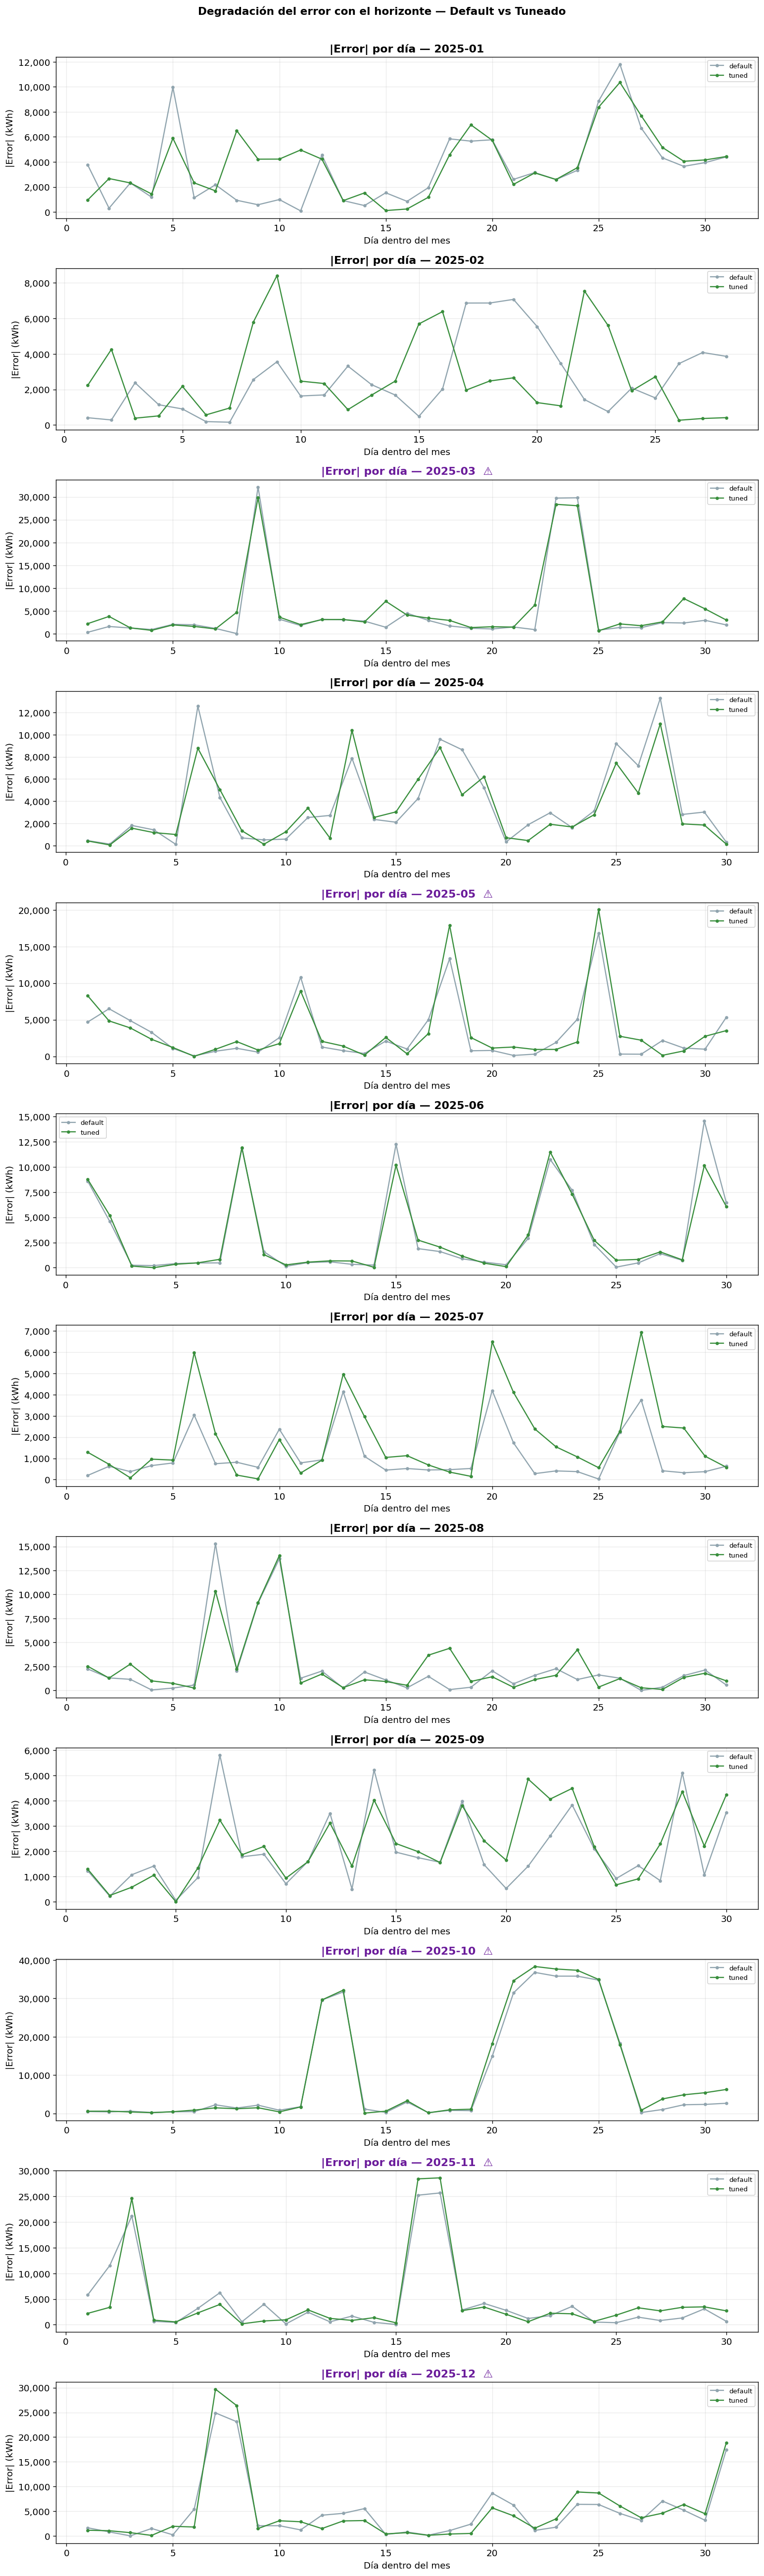

In [ ]:
n = len(PLOT_MONTHS)
fig, axes = plt.subplots(n, 1, figsize=(13, 3.6 * n), sharex=False)
axes = np.atleast_1d(axes)
for ax, mes in zip(axes, PLOT_MONTHS):
    dom = np.array([d.day for d in results[mes]['tuned']['dates']])
    for variant in VARIANTS:
        r = results[mes][variant]
        ax.plot(dom, np.abs(r['real'] - r['preds']), '-o', ms=3, lw=1.4, color=VCOLORS[variant], label=variant)
    tag = '  ⚠' if is_atyp(mes) else ''
    ax.set_title(f'|Error| por día — {mes}{tag}', fontweight='bold', color=(COLOR_ATYPICAL if is_atyp(mes) else 'black'))
    ax.set_xlabel('Día dentro del mes'); ax.set_ylabel('|Error| (kWh)'); ax.legend(fontsize=8); ax.grid(True, alpha=0.25)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.suptitle('Degradación del error con el horizonte — Default vs Tuneado', fontsize=13, fontweight='bold', y=1.003)
plt.tight_layout(); plt.savefig(out('error_horizonte.png'), dpi=150, bbox_inches='tight'); plt.show()

## 15. Tabla comparativa — Default vs Tuneado

In [ ]:
def _avg_metrics(variant, meses):
    return pd.DataFrame([results[m][variant]['metrics'] for m in meses]).mean()

rows = []
for mes in TEST_MONTHS:
    for variant in VARIANTS:
        rows.append({'Mes': mes, 'Atípico': is_atyp(mes), 'Variante': variant, **results[mes][variant]['metrics']})
metrics_df = pd.DataFrame(rows)
print("══ Métricas por mes (default vs tuned) ══")
print(metrics_df.to_string(index=False))
print("\n── Promedio sobre meses ESTABLES ──")
for variant in VARIANTS:
    a = _avg_metrics(variant, STABLE_MONTHS)
    print(f"  {variant:8s}: MAE={a['MAE']:,.0f}  RMSE={a['RMSE']:,.0f}  MAPE={a['MAPE (%)']:.2f}%  "
          f"WAPE={a['WAPE (%)']:.2f}%  MASE={a['MASE']:.3f}  R²={a['R²']:.4f}")

══ Métricas por mes (default vs tuned) ══
    Mes  Atípico Variante      MAE     RMSE  MAPE (%)  WAPE (%)   MASE     R²
2025-01    False  default  3431.22  4475.07    6.2567    5.3808 0.5948 0.8598
2025-01    False    tuned  3816.50  4528.47    6.6280    5.9850 0.6616 0.8564
2025-02    False  default  2557.72  3249.48    3.6831    3.7369 0.4445 0.9275
2025-02    False    tuned  2692.52  3522.51    4.7595    3.9339 0.4679 0.9148
2025-03     True  default  4616.58  9723.32    6.5142    6.6090 0.8075 0.0006
2025-03     True    tuned  5464.34  9546.28    7.9282    7.8226 0.9557 0.0366
2025-04    False  default  3789.95  5277.28    7.0569    5.7275 0.6634 0.8126
2025-04    False    tuned  3369.42  4619.07    6.1089    5.0920 0.5898 0.8564
2025-05     True  default  3094.98  5030.87    5.0799    4.4780 0.5406 0.7410
2025-05     True    tuned  3335.99  5663.31    5.4240    4.8267 0.5827 0.6718
2025-06    False  default  3163.77  5292.81    7.1025    4.9360 0.5546 0.8639
2025-06    False    tu

## 16. Métricas por mes estable — Default vs Tuneado

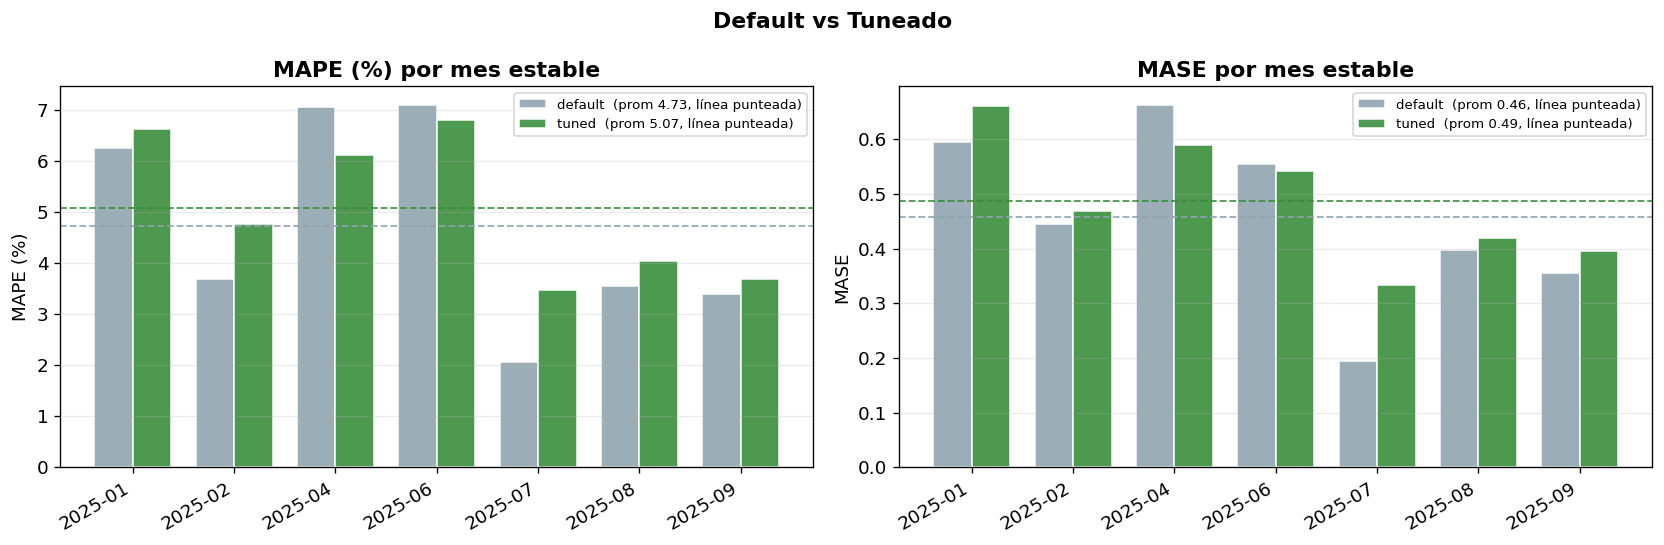

In [ ]:
stable = STABLE_MONTHS
x = np.arange(len(stable)); w = 0.38
fig, axes = plt.subplots(1, 2, figsize=(max(12, len(stable) * 2.0), 4.6))
for ax, met in zip(axes, ['MAPE (%)', 'MASE']):
    for k, variant in enumerate(VARIANTS):
        vals = [results[m][variant]['metrics'][met] for m in stable]
        avg = float(np.mean(vals))
        ax.bar(x + (k - 0.5) * w, vals, w, color=VCOLORS[variant], alpha=0.9, edgecolor='white',
               label=f'{variant}  (prom {avg:.2f}, línea punteada)')
        ax.axhline(avg, color=VCOLORS[variant], ls='--', lw=1.1, alpha=0.9)
    ax.set_xticks(x); ax.set_xticklabels(stable, rotation=30, ha='right')
    ax.set_ylabel(met); ax.set_title(f'{met} por mes estable', fontweight='bold')
    ax.legend(fontsize=8); ax.grid(True, axis='y', alpha=0.25)
plt.suptitle('Default vs Tuneado', fontweight='bold')
plt.tight_layout(); plt.savefig(out('comparativa_metricas.png'), dpi=150, bbox_inches='tight'); plt.show()

## 17. Heatmap MAPE — mes × variante

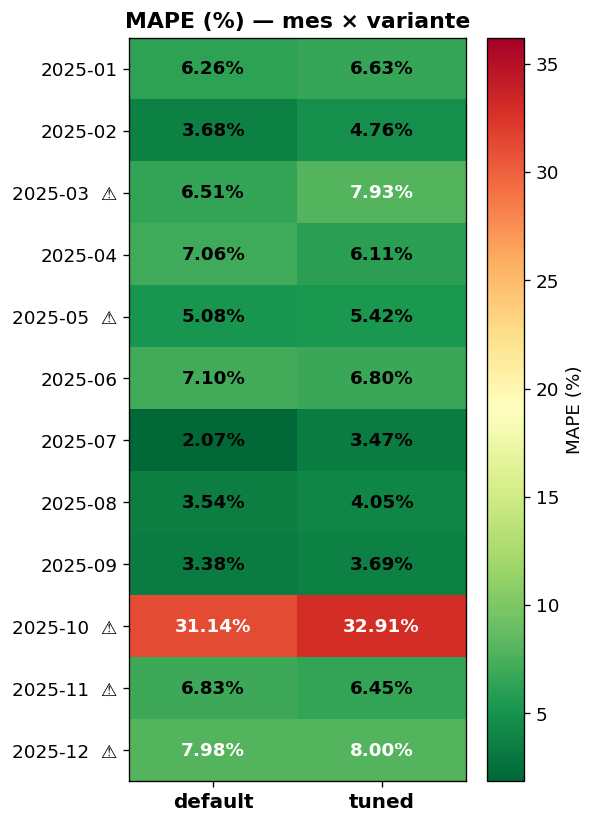

In [ ]:
mat = np.array([[results[m][v]['metrics']['MAPE (%)'] for v in VARIANTS] for m in TEST_MONTHS])
fig, ax = plt.subplots(figsize=(5, max(4, len(TEST_MONTHS) * 0.5 + 1)))
im = ax.imshow(mat, cmap='RdYlGn_r', aspect='auto', vmin=mat.min() * 0.9, vmax=mat.max() * 1.1)
ax.set_xticks(range(len(VARIANTS))); ax.set_xticklabels(VARIANTS, fontsize=12, fontweight='bold')
ax.set_yticks(range(len(TEST_MONTHS))); ax.set_yticklabels([f'{m}  ⚠' if is_atyp(m) else m for m in TEST_MONTHS])
for i in range(len(TEST_MONTHS)):
    for j in range(len(VARIANTS)):
        ax.text(j, i, f'{mat[i, j]:.2f}%', ha='center', va='center', fontweight='bold', fontsize=11,
                color='white' if mat[i, j] > mat.mean() else 'black')
plt.colorbar(im, ax=ax, label='MAPE (%)')
ax.set_title('MAPE (%) — mes × variante', fontweight='bold')
plt.tight_layout(); plt.savefig(out('heatmap_mape.png'), dpi=150, bbox_inches='tight'); plt.show()

## 18. Importancia de variables — modelo principal (meses estables)

- **A. MDI** (reducción de impureza en el entrenamiento), por variable y sumada por grupo.
- **B. Permutación sobre las entradas del pronóstico recursivo**: se baraja una variable (o un grupo) entre los días del
  mes y se mide cuánto sube el MAPE del consumo reconstruido. Las variables de calendario se miden igual que en SARIMAX.

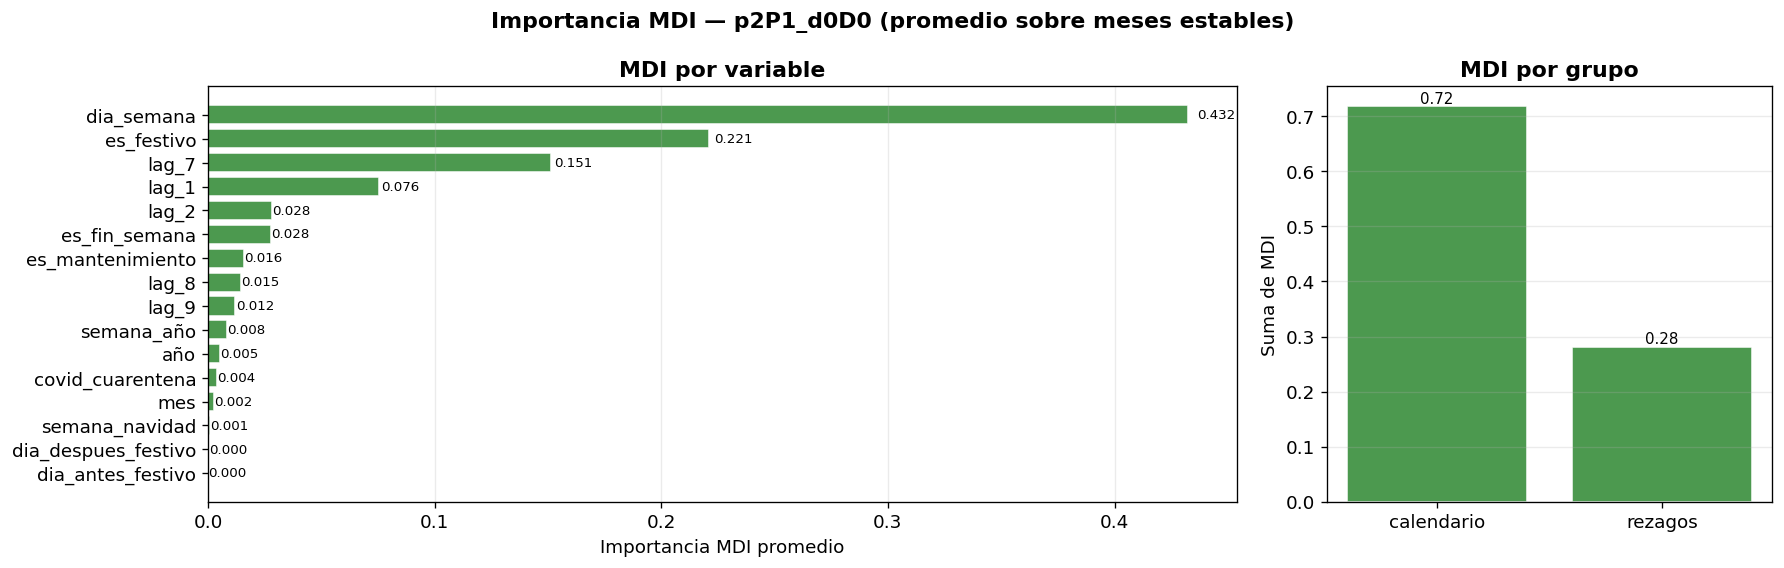

In [ ]:
mdi = pd.concat([results[m]['tuned']['mdi'] for m in STABLE_MONTHS], axis=1).mean(axis=1)
mdi_grp = {'calendario': mdi[CAL_COLS].sum()}
if SPEC.lag_names:
    mdi_grp['rezagos'] = mdi[SPEC.lag_names].sum()
mdi_grp = pd.Series(mdi_grp)
top = mdi.nlargest(min(25, len(mdi))).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, max(4.5, len(top) * 0.3)), gridspec_kw={'width_ratios': [3, 1.3]})
bars = axes[0].barh(top.index, top.values, color=RF_COLOR, alpha=0.9, edgecolor='white')
for b_, v in zip(bars, top.values):
    axes[0].text(v * 1.01, b_.get_y() + b_.get_height() / 2, f'{v:.3f}', va='center', fontsize=8)
axes[0].set_xlabel('Importancia MDI promedio'); axes[0].set_title('MDI por variable', fontweight='bold')
axes[0].grid(True, axis='x', alpha=0.25)
axes[1].bar(mdi_grp.index, mdi_grp.values, color=RF_COLOR, alpha=0.9, edgecolor='white')
for i, v in enumerate(mdi_grp.values):
    axes[1].text(i, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)
axes[1].set_ylabel('Suma de MDI'); axes[1].set_title('MDI por grupo', fontweight='bold'); axes[1].grid(True, axis='y', alpha=0.25)
plt.suptitle(f'Importancia MDI — {SPEC.name} (promedio sobre meses estables)', fontweight='bold')
plt.tight_layout(); plt.savefig(out('feature_importance_mdi.png'), dpi=150, bbox_inches='tight'); plt.show()

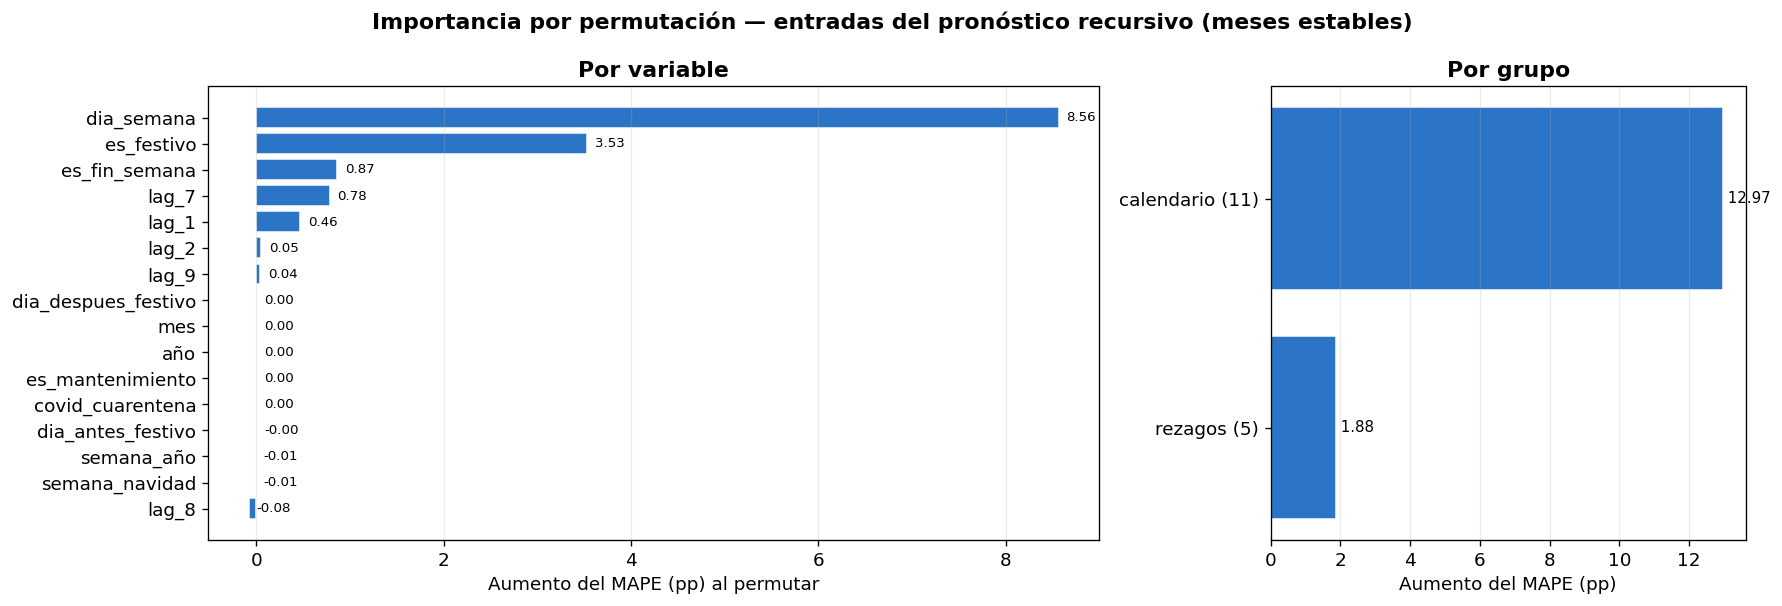

── Grupos (ΔMAPE pp) ──
GRUPO · calendario (11)    12.975
GRUPO · rezagos (5)         1.877

── Top 10 variables (ΔMAPE pp) ──
dia_semana             8.565
es_festivo             3.527
es_fin_semana          0.866
lag_7                  0.782
lag_1                  0.464
lag_2                  0.052
lag_9                  0.038
dia_despues_festivo    0.002
mes                    0.000
año                    0.000


In [ ]:
perm = pd.concat([pd.Series(results[m]['tuned']['perm']) for m in STABLE_MONTHS], axis=1).mean(axis=1)
perm_grp = perm[[g for g in perm.index if g.startswith('GRUPO')]].sort_values()
perm_var = perm[[g for g in perm.index if not g.startswith('GRUPO')]]
perm_top = perm_var.nlargest(min(20, len(perm_var))).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, max(4.5, len(perm_top) * 0.32)), gridspec_kw={'width_ratios': [3, 1.6]})
bars = axes[0].barh(perm_top.index, perm_top.values, color='#1565C0', alpha=0.9, edgecolor='white')
_xm = max(perm_top.values.max(), 1e-9)
for b_, v in zip(bars, perm_top.values):
    axes[0].text(v + _xm * 0.01, b_.get_y() + b_.get_height() / 2, f'{v:.2f}', va='center', fontsize=8)
axes[0].set_xlabel('Aumento del MAPE (pp) al permutar'); axes[0].set_title('Por variable', fontweight='bold')
axes[0].grid(True, axis='x', alpha=0.25)
bars = axes[1].barh(perm_grp.index.str.replace('GRUPO · ', ''), perm_grp.values, color='#1565C0', alpha=0.9, edgecolor='white')
for b_, v in zip(bars, perm_grp.values):
    axes[1].text(v, b_.get_y() + b_.get_height() / 2, f' {v:.2f}', va='center', fontsize=9)
axes[1].set_xlabel('Aumento del MAPE (pp)'); axes[1].set_title('Por grupo', fontweight='bold'); axes[1].grid(True, axis='x', alpha=0.25)
plt.suptitle('Importancia por permutación — entradas del pronóstico recursivo (meses estables)', fontweight='bold')
plt.tight_layout(); plt.savefig(out('feature_importance_perm.png'), dpi=150, bbox_inches='tight'); plt.show()

imp_df = pd.DataFrame({'perm_dMAPE_pp': perm, 'MDI': mdi.reindex(perm.index)}).sort_values('perm_dMAPE_pp', ascending=False)
imp_df.to_csv(out('feature_importance.csv'))
print("── Grupos (ΔMAPE pp) ──"); print(perm_grp.sort_values(ascending=False).round(3).to_string())
print("\n── Top 10 variables (ΔMAPE pp) ──"); print(perm_var.nlargest(10).round(3).to_string())

## 19. APE promedio por horizonte — Default vs Tuneado (meses estables)

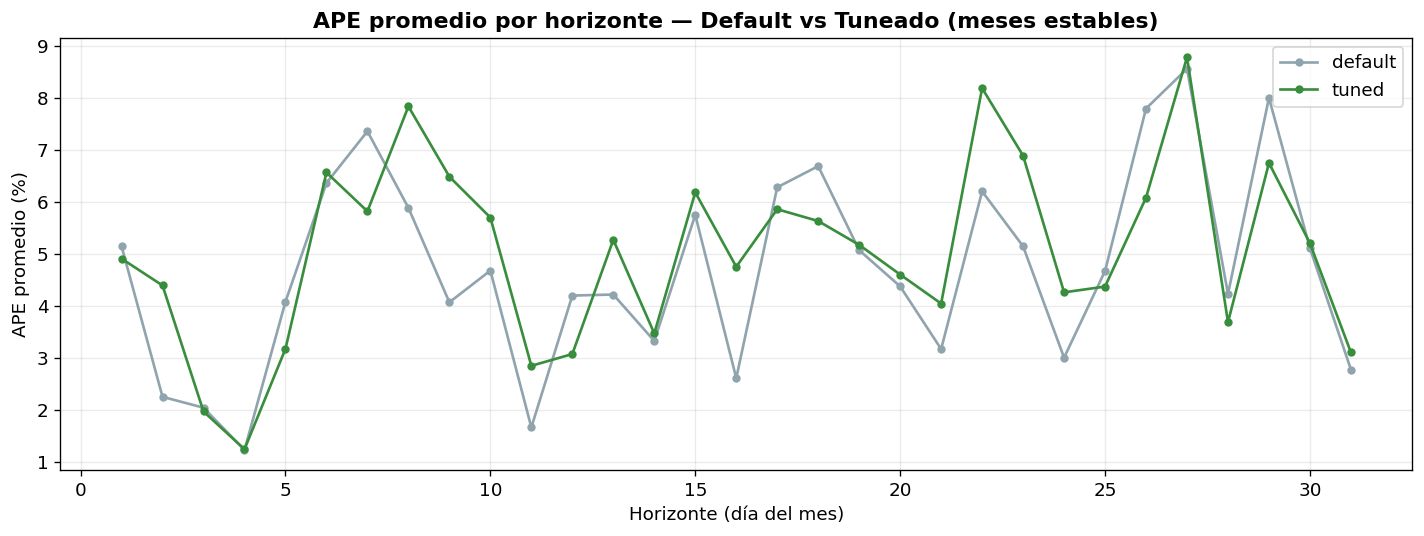

In [ ]:
records = []
for mes in STABLE_MONTHS:
    for variant in VARIANTS:
        r = results[mes][variant]
        for d, rl, pr in zip(r['dates'], r['real'], r['preds']):
            records.append({'dom': d.day, 'variant': variant, 'ape': abs(rl - pr) / rl * 100})
ape_df = pd.DataFrame(records)
fig, ax = plt.subplots(figsize=(12, 4.6))
for variant in VARIANTS:
    g = ape_df[ape_df['variant'] == variant].groupby('dom')['ape'].mean()
    ax.plot(g.index, g.values, '-o', ms=4, lw=1.6, color=VCOLORS[variant], label=variant)
ax.set_xlabel('Horizonte (día del mes)'); ax.set_ylabel('APE promedio (%)')
ax.set_title('APE promedio por horizonte — Default vs Tuneado (meses estables)', fontweight='bold')
ax.legend(); ax.grid(True, alpha=0.25)
plt.tight_layout(); plt.savefig(out('ape_horizonte.png'), dpi=150, bbox_inches='tight'); plt.show()

## 20. Comparación directa por mes — Default vs Tuneado

In [ ]:
rows = []
for mes in TEST_MONTHS:
    md_, mt_ = results[mes]['default']['metrics']['MAPE (%)'], results[mes]['tuned']['metrics']['MAPE (%)']
    rows.append({'Mes': mes, 'Atípico': is_atyp(mes), 'MAPE default': round(md_, 2), 'MAPE tuned': round(mt_, 2),
                 'Δ': round(mt_ - md_, 2), '% mejora': round((md_ - mt_) / md_ * 100, 1),
                 'MASE default': results[mes]['default']['metrics']['MASE'], 'MASE tuned': results[mes]['tuned']['metrics']['MASE']})
cmp_df = pd.DataFrame(rows)
print(cmp_df.to_string(index=False))
md_avg = np.mean([results[m]['default']['metrics']['MAPE (%)'] for m in STABLE_MONTHS])
mt_avg = np.mean([results[m]['tuned']['metrics']['MAPE (%)'] for m in STABLE_MONTHS])
d_pair = np.array([results[m]['tuned']['metrics']['MAPE (%)'] - results[m]['default']['metrics']['MAPE (%)'] for m in STABLE_MONTHS])
se_pair = d_pair.std(ddof=1) / np.sqrt(len(d_pair)) if len(d_pair) > 1 else np.nan
print(f"\n(meses estables)  MAPE default = {md_avg:.2f}%  |  tuned = {mt_avg:.2f}%  |  "
      f"diferencia pareada = {d_pair.mean():+.2f} ± {se_pair:.2f} pp (SE)")

    Mes  Atípico  MAPE default  MAPE tuned     Δ  % mejora  MASE default  MASE tuned
2025-01    False          6.26        6.63  0.37      -5.9        0.5948      0.6616
2025-02    False          3.68        4.76  1.08     -29.2        0.4445      0.4679
2025-03     True          6.51        7.93  1.41     -21.7        0.8075      0.9557
2025-04    False          7.06        6.11 -0.95      13.4        0.6634      0.5898
2025-05     True          5.08        5.42  0.34      -6.8        0.5406      0.5827
2025-06    False          7.10        6.80 -0.30       4.2        0.5546      0.5412
2025-07    False          2.07        3.47  1.40     -67.7        0.1943      0.3326
2025-08    False          3.54        4.05  0.51     -14.3        0.3970      0.4191
2025-09    False          3.38        3.69  0.30      -9.0        0.3545      0.3946
2025-10     True         31.14       32.91  1.77      -5.7        1.6949      1.8257
2025-11     True          6.83        6.45 -0.39       5.6       

---
# E. Análisis adicionales

## 21. Comparación de modelos y estrategias (meses estables)

| Clave | Qué es | Para qué sirve |
|---|---|---|
| `rf_malla` | Modelo principal, pronóstico recursivo | El pronóstico del RF con la memoria del SARIMAX. |
| `rf_calendario` | Referencia tuneada, sin historia | Mide si la historia aporta: si no supera a `rf_calendario`, la historia no está ayudando. |
| `rf_memoria70` | Referencia tuneada, memoria de 70 días | Mide cuánto cambia el RF si mira más allá de la malla del SARIMAX. |
| `oraculo` | Modelo principal con los valores **reales** del mes | **No es un pronóstico válido.** La brecha con `rf_malla` es el costo de reinyectar predicciones. |
| `naive` | Repetir la última semana observada | Piso mínimo. |

══ Promedio sobre meses estables ══
                     MAPE (%)  WAPE (%)   MASE       MAE
Modelo                                                  
RF malla SARIMAX        5.072     4.200  0.487  2780.266
RF solo calendario      5.819     5.000  0.578  3302.814
RF memoria 70 días      5.302     4.457  0.516  2949.670
Oráculo (no válido)     3.751     3.072  0.357  2036.437
Ingenuo estacional      9.458     7.919  0.909  5199.304

══ MAPE por mes estable ══
Modelo   RF malla SARIMAX  RF solo calendario  RF memoria 70 días  Oráculo (no válido)  Ingenuo estacional
Mes                                                                                                       
2025-01              6.63               10.18                7.51                 4.63               15.10
2025-02              4.76                6.18                4.75                 3.47                4.48
2025-04              6.11                4.12                5.46                 4.46                8.69
20

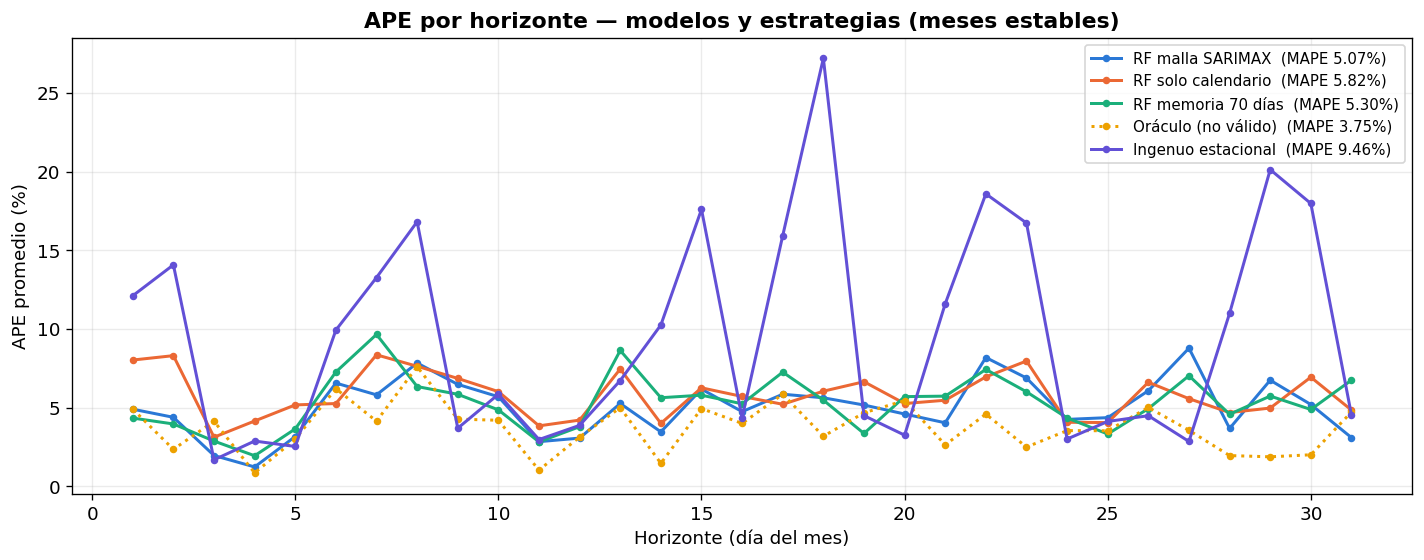

Costo de la recursión (malla − oráculo)                     : +1.32 pp
Aporte de la historia (calendario − malla)                  : +0.75 pp   (positivo = la historia ayuda)
Aporte de mirar más atrás (malla − memoria 70 días)         : -0.23 pp   (positivo = la memoria larga ayuda)
Ganancia frente al ingenuo estacional (naive − malla)       : +4.39 pp
✓ El RF principal supera al ingenuo estacional (MAPE medio, meses estables)


In [ ]:
MOD_KEYS = ['rf_malla', 'rf_calendario', 'rf_memoria70', 'oraculo', 'naive']
MOD_LAB = {'rf_malla': 'RF malla SARIMAX', 'rf_calendario': 'RF solo calendario', 'rf_memoria70': 'RF memoria 70 días',
           'oraculo': 'Oráculo (no válido)', 'naive': 'Ingenuo estacional'}
MCOL = dict(zip(MOD_KEYS, CAT))
mod_rows = []
for mes in TEST_MONTHS:
    r = results[mes]['tuned']
    for k in MOD_KEYS:
        mod_rows.append({'Mes': mes, 'Atípico': is_atyp(mes), 'Modelo': k, **compute_metrics(r['real'], r['modelos'][k], r['scale'])})
mod_df = pd.DataFrame(mod_rows)
mod_stable = mod_df[~mod_df['Atípico']].groupby('Modelo')[['MAPE (%)', 'WAPE (%)', 'MASE', 'MAE']].mean().reindex(MOD_KEYS)
print("══ Promedio sobre meses estables ══"); print(mod_stable.rename(index=MOD_LAB).round(3).to_string())
print("\n══ MAPE por mes estable ══")
print(mod_df[~mod_df['Atípico']].pivot(index='Mes', columns='Modelo', values='MAPE (%)')[MOD_KEYS]
      .rename(columns=MOD_LAB).round(2).to_string())

rec = []
for mes in STABLE_MONTHS:
    r = results[mes]['tuned']
    for k in MOD_KEYS:
        for d, rl, pr in zip(r['dates'], r['real'], r['modelos'][k]):
            rec.append({'dom': d.day, 'Modelo': k, 'ape': abs(rl - pr) / rl * 100})
ape_m = pd.DataFrame(rec)
fig, ax = plt.subplots(figsize=(12, 4.8))
for k in MOD_KEYS:
    g = ape_m[ape_m['Modelo'] == k].groupby('dom')['ape'].mean()
    ax.plot(g.index, g.values, ':' if k == 'oraculo' else '-', marker='o', ms=3.5, lw=1.8, color=MCOL[k],
            label=f"{MOD_LAB[k]}  (MAPE {mod_stable.loc[k, 'MAPE (%)']:.2f}%)")
ax.set_xlabel('Horizonte (día del mes)'); ax.set_ylabel('APE promedio (%)')
ax.set_title('APE por horizonte — modelos y estrategias (meses estables)', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.25)
plt.tight_layout(); plt.savefig(out('modelos_estrategias.png'), dpi=150, bbox_inches='tight'); plt.show()

g = lambda k: mod_stable.loc[k, 'MAPE (%)']
print(f"Costo de la recursión (malla − oráculo)                     : {g('rf_malla') - g('oraculo'):+.2f} pp")
print(f"Aporte de la historia (calendario − malla)                  : {g('rf_calendario') - g('rf_malla'):+.2f} pp   (positivo = la historia ayuda)")
print(f"Aporte de mirar más atrás (malla − memoria 70 días)         : {g('rf_malla') - g('rf_memoria70'):+.2f} pp   (positivo = la memoria larga ayuda)")
print(f"Ganancia frente al ingenuo estacional (naive − malla)       : {g('naive') - g('rf_malla'):+.2f} pp")
check('El RF principal supera al ingenuo estacional (MAPE medio, meses estables)', g('rf_malla') < g('naive'))

## 22. Sesgo por tipo de día (meses estables)

Error porcentual **con signo**: (predicción − real) / real × 100. Positivo indica sobreestimación. Se comparan los tres RF.
Si el modelo principal usa diferenciación semanal (`D` = 1), debería sufrir menos el cambio de nivel de 2025.

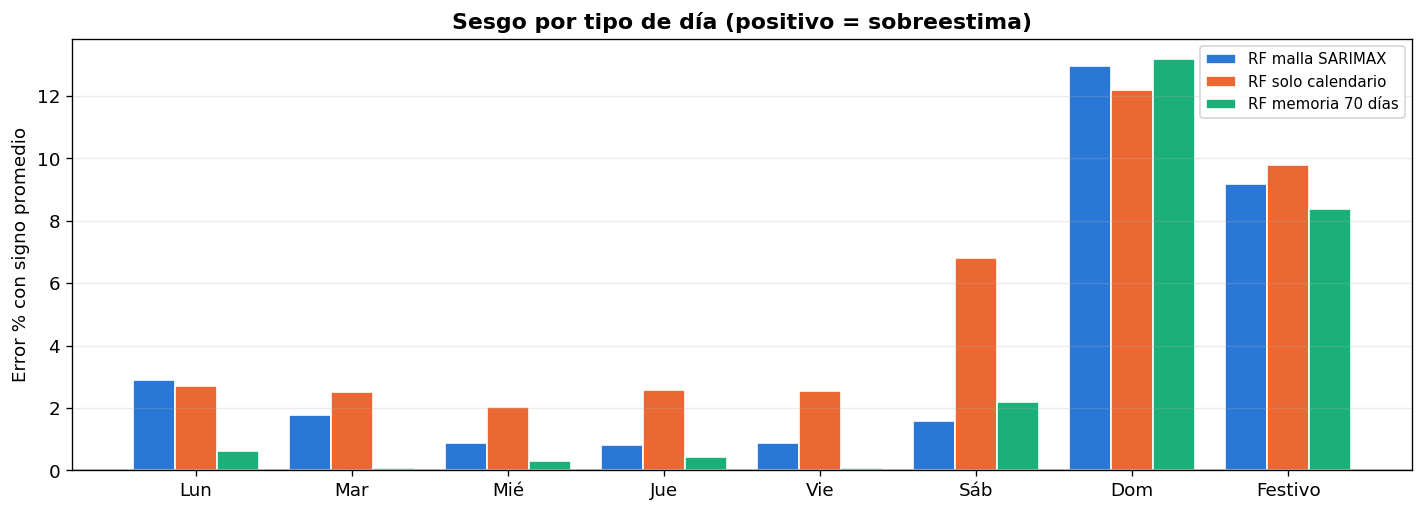

Modelo   RF malla SARIMAX  RF solo calendario  RF memoria 70 días
tipo                                                             
Lun                  2.89                2.71                0.61
Mar                  1.77                2.51                0.06
Mié                  0.89                2.02                0.31
Jue                  0.81                2.57                0.43
Vie                  0.87                2.56                0.06
Sáb                  1.57                6.79                2.20
Dom                 12.96               12.18               13.18
Festivo              9.19                9.77                8.38

Sesgo global (meses estables): RF malla SARIMAX=+3.39%  RF solo calendario=+4.74%  RF memoria 70 días=+2.70%


In [ ]:
DIAS = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
RF_KEYS = ['rf_malla', 'rf_calendario', 'rf_memoria70']
rows = []
for mes in STABLE_MONTHS:
    r = results[mes]['tuned']
    fest = SERIE.cal.loc[r['dates'], 'es_festivo'].to_numpy()
    for k in RF_KEYS:
        for d, rl, pr, f in zip(r['dates'], r['real'], r['modelos'][k], fest):
            rows.append({'Modelo': k, 'tipo': 'Festivo' if f else DIAS[d.weekday()], 'spe': (pr - rl) / rl * 100})
bias = pd.DataFrame(rows)
tipos = DIAS + ['Festivo']
tab = bias.groupby(['tipo', 'Modelo'])['spe'].mean().unstack().reindex(index=tipos, columns=RF_KEYS)

xx = np.arange(len(tipos)); w = 0.27
fig, ax = plt.subplots(figsize=(12, 4.4))
for i, k in enumerate(RF_KEYS):
    ax.bar(xx + (i - 1) * w, tab[k].fillna(0).values, w, color=CAT[i], label=MOD_LAB[k], edgecolor='white')
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(xx); ax.set_xticklabels(tipos)
ax.set_ylabel('Error % con signo promedio'); ax.legend(fontsize=9); ax.grid(True, axis='y', alpha=0.25)
ax.set_title('Sesgo por tipo de día (positivo = sobreestima)', fontweight='bold')
plt.tight_layout(); plt.savefig(out('sesgo_tipo_dia.png'), dpi=150, bbox_inches='tight'); plt.show()
print(tab.rename(columns=MOD_LAB).round(2).to_string())
print("\nSesgo global (meses estables): " + "  ".join(f"{MOD_LAB[k]}={bias[bias['Modelo']==k]['spe'].mean():+.2f}%" for k in RF_KEYS))

## 23. Malla en test (solo diagnóstico)

Estructuras de la malla evaluadas en 2025 con los hiperparámetros por defecto, como en la sección 8. **No se usa para
decidir nada**. Sirve para ver si el ranking de 2024 se sostiene fuera de muestra.

estructura  n_rezagos  d  D  MAPE CV (%)  preseleccionada  elegida  MAPE test (%)  MASE test
 p2P1_d0D0          5  0  0        3.785             True     True          4.910      0.483
 p1P1_d0D0          3  0  0        4.004             True    False          5.988      0.573
 p2P2_d0D0          8  0  0        4.036             True    False          5.247      0.486
 p1P0_d0D0          1  0  0        4.124             True    False          6.422      0.629
 p4P0_d0D0          4  0  0        4.234             True    False          5.610      0.527

Correlación de Spearman entre el ranking CV y el ranking test: 0.50


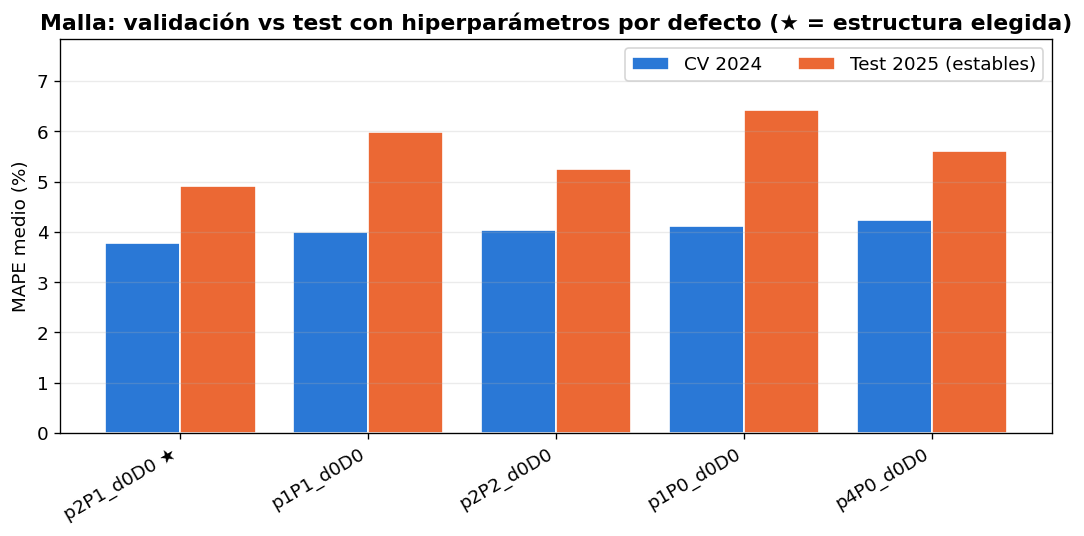

In [ ]:
if RUN_GRID_ON_TEST in ('preseleccion', 'todas'):
    specs_t = GRID if RUN_GRID_ON_TEST == 'todas' else [SPEC_BY_NAME[e] for e in SHORTLIST]
    lt_rows = []; t0 = time.time()
    for spec in specs_t:
        mets = []
        for mes in STABLE_MONTHS:
            cutoff = pd.Timestamp(f'{mes}-01'); dates = month_dates(mes)
            model = fit_rf(SKLEARN_DEFAULT_RF, spec, cutoff, n_estimators=GRID_N_ESTIMATORS)
            yh = forecast_recursive(model, spec, cutoff, dates)[0]
            mets.append(compute_metrics(SERIE.y.loc[dates].to_numpy(), yh, mase_scale(cutoff)))
            del model
        a = pd.DataFrame(mets)
        lt_rows.append({'estructura': spec.name, 'MAPE test (%)': a['MAPE (%)'].mean(), 'MASE test': a['MASE'].mean()})
    grid_test_df = grid_df[['estructura', 'n_rezagos', 'd', 'D', 'MAPE (%)', 'preseleccionada', 'elegida']].rename(
        columns={'MAPE (%)': 'MAPE CV (%)'}).merge(pd.DataFrame(lt_rows), on='estructura')
    TIEMPOS['23. Malla en test'] = (time.time() - t0) / 60
    print(grid_test_df.sort_values('MAPE CV (%)').round(3).to_string(index=False))
    if len(grid_test_df) >= 3:
        rho = float(stats.spearmanr(grid_test_df['MAPE CV (%)'], grid_test_df['MAPE test (%)'])[0])
        print(f"\nCorrelación de Spearman entre el ranking CV y el ranking test: {rho:.2f}")
    grid_test_df.to_csv(out('malla_estructuras_test.csv'), index=False)

    gt = grid_test_df.sort_values('MAPE CV (%)').head(15)
    xx = np.arange(len(gt)); w = 0.4
    fig, ax = plt.subplots(figsize=(max(9, len(gt) * 0.9), 4.6))
    ax.bar(xx - w / 2, gt['MAPE CV (%)'], w, color=CAT[0], label='CV 2024', edgecolor='white')
    ax.bar(xx + w / 2, gt['MAPE test (%)'], w, color=CAT[1], label='Test 2025 (estables)', edgecolor='white')
    ax.set_xticks(xx); ax.set_xticklabels([e + (' ★' if el else '') for e, el in zip(gt['estructura'], gt['elegida'])],
                                          rotation=30, ha='right')
    ax.set_ylim(0, max(gt['MAPE CV (%)'].max(), gt['MAPE test (%)'].max()) * 1.22)
    ax.set_ylabel('MAPE medio (%)'); ax.legend(ncol=2, loc='upper right'); ax.grid(True, axis='y', alpha=0.25)
    ax.set_title('Malla: validación vs test con hiperparámetros por defecto (★ = estructura elegida)', fontweight='bold')
    plt.tight_layout(); plt.savefig(out('malla_cv_vs_test.png'), dpi=150, bbox_inches='tight'); plt.show()
else:
    grid_test_df = None
    print("RUN_GRID_ON_TEST = 'ninguna' → se omite.")

## 24. Intervalos — confianza del MAPE mensual y bandas de pronóstico

**A. Intervalo del MAPE mensual** (default y tuneado, con y sin atípicos): IC del MAPE medio e IP del MAPE de un mes nuevo.

**B. Banda conformal por día de la semana.** Es la misma función portable de SARIMAX, calibrada con los residuos
recursivos fuera de muestra del modelo principal en los **24 meses** de la confirmación (2023–2024). Con dos años de
residuos, la banda recoge mejor la variación entre años que con uno solo.

══ INTERVALOS DEL MAPE MENSUAL (nivel 90%) ══
Variante    Escenario  n  MAPE medio  MAPE mediana  std  min   max   IC90% media  IP90% un mes
 default Con atípicos 12        7.55          6.39 7.66 2.07 31.14 [3.58, 11.52] [0.00, 21.86]
 default Sin atípicos  7        4.73          3.68 2.03 2.07  7.10  [3.23, 6.22]  [0.50, 8.95]
   tuned Con atípicos 12        8.02          6.28 7.99 3.47 32.91 [3.88, 12.16] [0.00, 22.95]
   tuned Sin atípicos  7        5.07          4.76 1.42 3.47  6.80  [4.03, 6.12]  [2.12, 8.03]


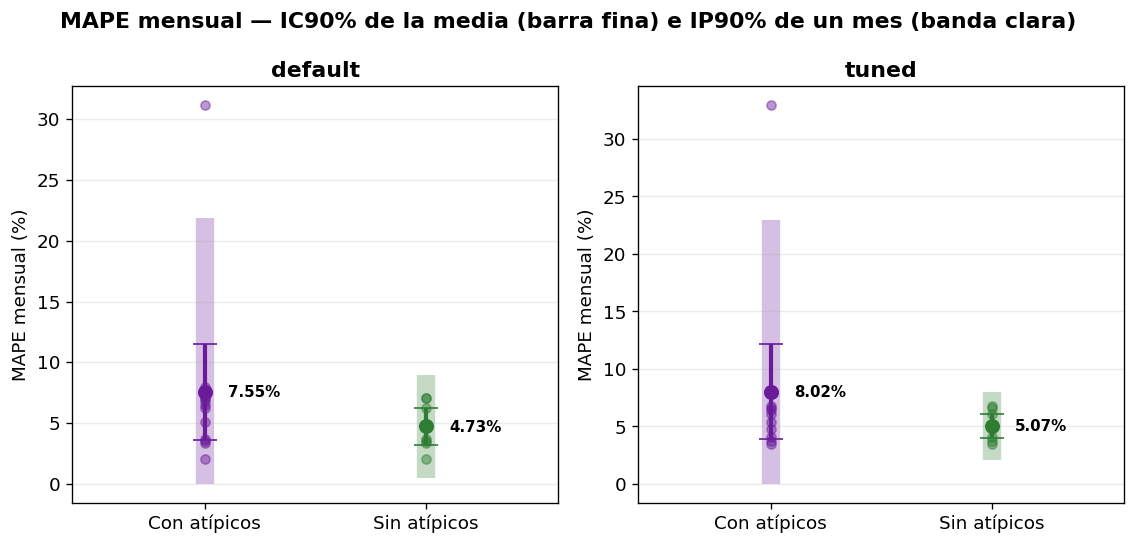

In [ ]:
Z = CI_LEVEL; pct = int(round(Z * 100))

def _intervalos(vals, level=Z):
    vals = np.asarray(vals, float); n = len(vals)
    mean, med = float(np.mean(vals)), float(np.median(vals))
    sd = float(np.std(vals, ddof=1)) if n > 1 else 0.0
    o = {'n': n, 'media': mean, 'mediana': med, 'std': sd, 'min': float(vals.min()), 'max': float(vals.max()),
         'ic_media': (mean, mean), 'ip_mes': (mean, mean), 'vals': vals}
    if n > 1:
        t = float(stats.t.ppf(0.5 + level / 2, df=n - 1))
        o['ic_media'] = (mean - t * sd / np.sqrt(n), mean + t * sd / np.sqrt(n))
        o['ip_mes']   = (mean - t * sd * np.sqrt(1 + 1 / n), mean + t * sd * np.sqrt(1 + 1 / n))
    return o

_esc = {'Con atípicos': TEST_MONTHS, 'Sin atípicos': STABLE_MONTHS}
_store, _rows = {}, []
for variant in VARIANTS:
    _store[variant] = {}
    for esc, meses in _esc.items():
        s = _intervalos([results[m][variant]['metrics']['MAPE (%)'] for m in meses]); _store[variant][esc] = s
        ic = (max(0.0, s['ic_media'][0]), s['ic_media'][1]); ip = (max(0.0, s['ip_mes'][0]), s['ip_mes'][1])
        _rows.append({'Variante': variant, 'Escenario': esc, 'n': s['n'], 'MAPE medio': round(s['media'], 2),
                      'MAPE mediana': round(s['mediana'], 2), 'std': round(s['std'], 2), 'min': round(s['min'], 2),
                      'max': round(s['max'], 2), f'IC{pct}% media': f"[{ic[0]:.2f}, {ic[1]:.2f}]",
                      f'IP{pct}% un mes': f"[{ip[0]:.2f}, {ip[1]:.2f}]"})
ic_mape_df = pd.DataFrame(_rows)
print(f"══ INTERVALOS DEL MAPE MENSUAL (nivel {pct}%) ══"); print(ic_mape_df.to_string(index=False))
ic_mape_df.to_csv(out('intervalos_mape.csv'), index=False)

fig, axes = plt.subplots(1, len(VARIANTS), figsize=(4.8 * len(VARIANTS), 4.6))
offsets = {'Con atípicos': 0.0, 'Sin atípicos': 1.0}
ecol = {'Con atípicos': COLOR_ATYPICAL, 'Sin atípicos': '#2E7D32'}
for ax, variant in zip(np.atleast_1d(axes), VARIANTS):
    for esc in _esc:
        s = _store[variant][esc]; xo = offsets[esc]; m = s['media']
        ic = (max(0.0, s['ic_media'][0]), s['ic_media'][1]); ip = (max(0.0, s['ip_mes'][0]), s['ip_mes'][1])
        ax.scatter(np.full(len(s['vals']), xo), s['vals'], color=ecol[esc], alpha=0.45, s=30, zorder=2)
        ax.errorbar(xo, m, yerr=[[m - ip[0]], [ip[1] - m]], fmt='none', ecolor=ecol[esc], alpha=0.28, elinewidth=11, zorder=1)
        ax.errorbar(xo, m, yerr=[[m - ic[0]], [ic[1] - m]], fmt='o', color=ecol[esc], ecolor=ecol[esc],
                    elinewidth=2.5, capsize=7, ms=8, zorder=3)
        ax.annotate(f"{m:.2f}%", (xo, m), textcoords='offset points', xytext=(14, -3), fontsize=9, fontweight='bold')
    ax.set_xticks(list(offsets.values())); ax.set_xticklabels(list(offsets.keys())); ax.set_xlim(-0.6, 1.6)
    ax.set_ylabel('MAPE mensual (%)'); ax.set_title(variant, fontweight='bold'); ax.grid(True, axis='y', alpha=0.25)
plt.suptitle(f'MAPE mensual — IC{pct}% de la media (barra fina) e IP{pct}% de un mes (banda clara)', fontweight='bold')
plt.tight_layout(); plt.savefig(out('intervalos_mape.png'), dpi=150, bbox_inches='tight'); plt.show()

Calibración: 731 residuos recursivos fuera de muestra (2023-01 … 2024-12), sin reentrenar.


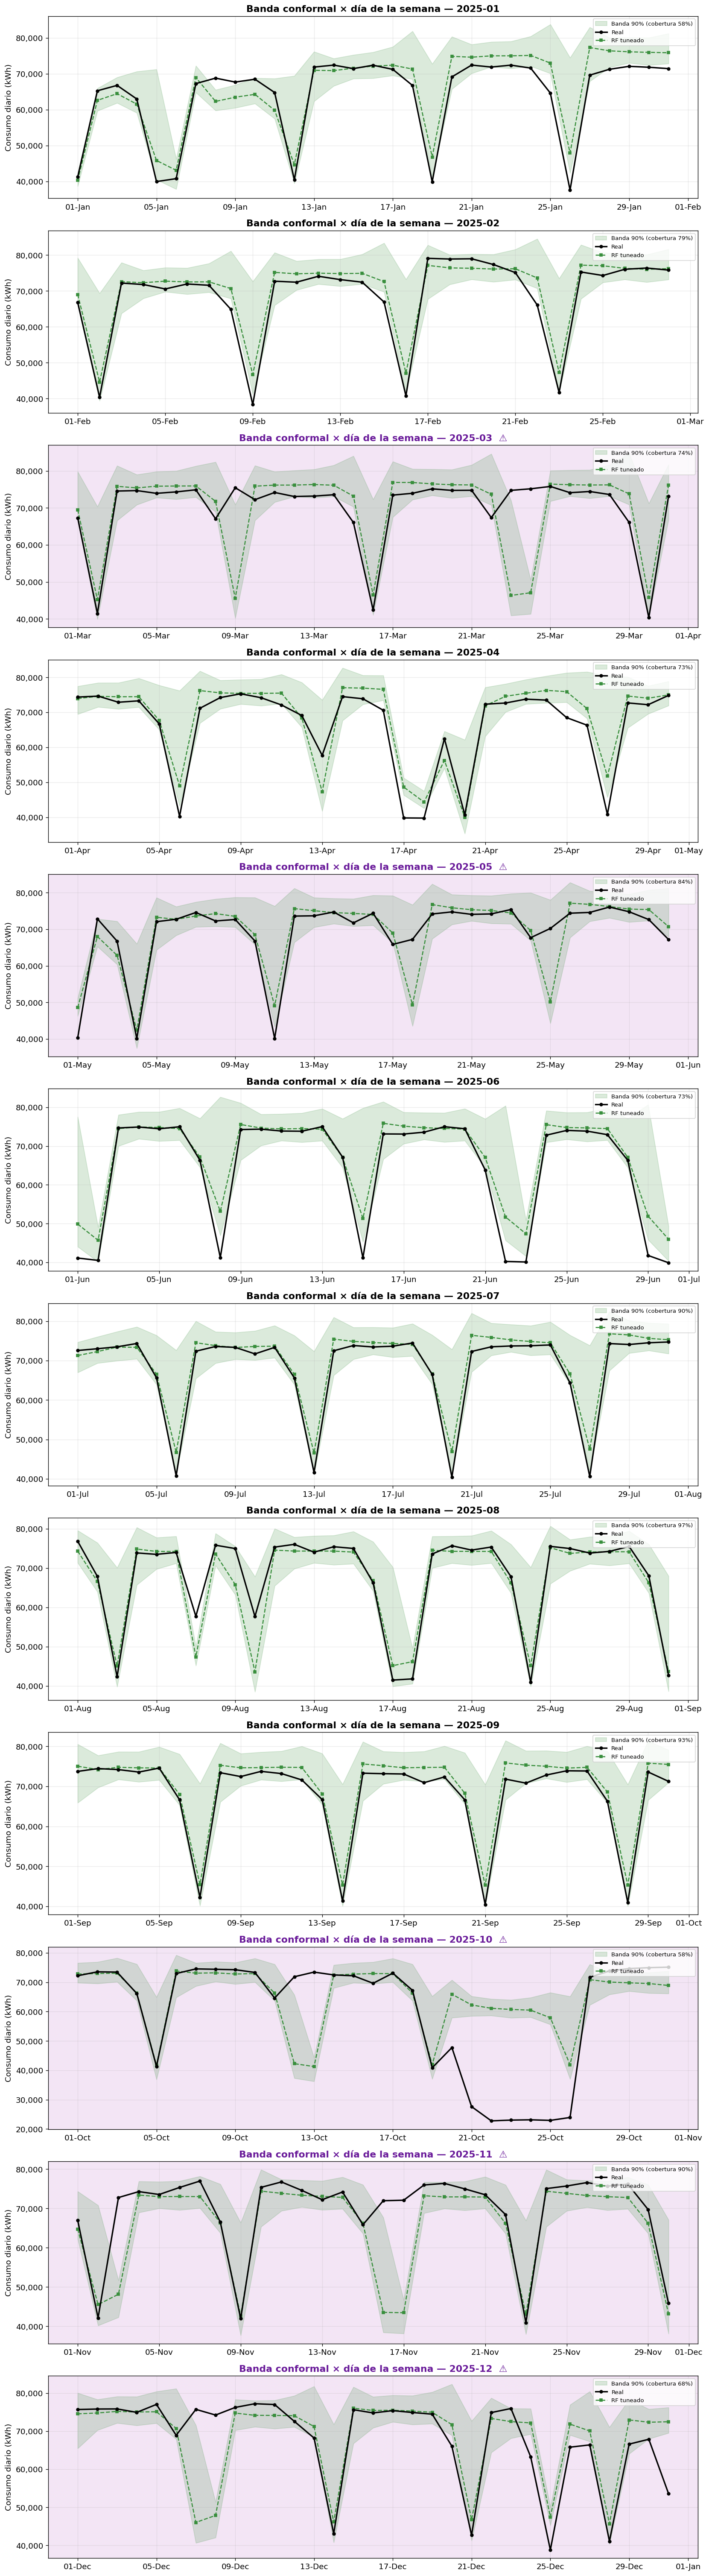

    Mes  Atípico  Cobertura (%)  Ancho medio (kWh)
2025-01    False           58.1            11673.0
2025-02    False           78.6            12890.0
2025-03     True           74.2            13424.0
2025-04    False           73.3            12237.0
2025-05     True           83.9            12480.0
2025-06    False           73.3            13442.0
2025-07    False           90.3            12251.0
2025-08    False           96.8            12653.0
2025-09    False           93.3            12602.0
2025-10     True           58.1            11165.0
2025-11     True           90.0            12520.0
2025-12     True           67.7            12217.0

══ Cobertura empírica 90% (meses estables): 80.5%  (objetivo 90%) ══


In [ ]:
PI = CI_LEVEL

def weekday_conformal_bands(cal_dates, cal_real, cal_pred, target_dates, target_pred,
                            level=PI, mode='relative', min_group=15):
    """Misma función portable que en SARIMAX: cuantiles de residuos fuera de muestra por día de la semana."""
    a = 1 - level; ql, qh = a / 2, 1 - a / 2
    cal_real = np.asarray(cal_real, float); cal_pred = np.asarray(cal_pred, float)
    cal_wd = pd.DatetimeIndex(cal_dates).weekday.to_numpy()
    if mode == 'relative':
        ok = cal_pred != 0
        resid = (cal_real[ok] - cal_pred[ok]) / cal_pred[ok]; cal_wd = cal_wd[ok]
    else:
        resid = cal_real - cal_pred
    g_lo, g_hi = np.quantile(resid, ql), np.quantile(resid, qh)
    lo_wd, hi_wd = {}, {}
    for w in range(7):
        r = resid[cal_wd == w]
        lo_wd[w], hi_wd[w] = (np.quantile(r, ql), np.quantile(r, qh)) if len(r) >= min_group else (g_lo, g_hi)
    tp = np.asarray(target_pred, float); twd = pd.DatetimeIndex(target_dates).weekday.to_numpy()
    lo = np.array([lo_wd[w] for w in twd]); hi = np.array([hi_wd[w] for w in twd])
    return (tp * (1 + lo), tp * (1 + hi)) if mode == 'relative' else (tp + lo, tp + hi)

cal_D = pd.DatetimeIndex(np.concatenate([np.asarray(d) for d, _, _ in CAL_PREDS]))
cal_R = np.concatenate([r for _, r, _ in CAL_PREDS]); cal_P = np.concatenate([p for _, _, p in CAL_PREDS])
print(f"Calibración: {len(cal_R)} residuos recursivos fuera de muestra ({CONFIRM_MONTHS[0]} … {CONFIRM_MONTHS[-1]}), sin reentrenar.")

n = len(PLOT_MONTHS)
fig, axes = plt.subplots(n, 1, figsize=(14, 4.2 * n), sharex=False)
cov_rows = []
for ax, mes in zip(np.atleast_1d(axes), PLOT_MONTHS):
    r = results[mes]['tuned']
    lo, hi = weekday_conformal_bands(cal_D, cal_R, cal_P, r['dates'], r['preds'], level=PI)
    cov = float(np.mean((r['real'] >= lo) & (r['real'] <= hi)) * 100)
    cov_rows.append({'Mes': mes, 'Atípico': is_atyp(mes), 'Cobertura (%)': round(cov, 1),
                     'Ancho medio (kWh)': round(float(np.mean(hi - lo)), 0)})
    ax.fill_between(r['dates'], lo, hi, color=RF_COLOR, alpha=0.18, label=f'Banda {int(PI*100)}% (cobertura {cov:.0f}%)')
    ax.plot(r['dates'], r['real'], 'k-o', lw=2, ms=4, label='Real', zorder=5)
    ax.plot(r['dates'], r['preds'], '--s', color=RF_COLOR, ms=3.5, lw=1.5, label='RF tuneado')
    tag = '  ⚠' if is_atyp(mes) else ''
    ax.set_title(f'Banda conformal × día de la semana — {mes}{tag}', fontweight='bold',
                 color=(COLOR_ATYPICAL if is_atyp(mes) else 'black'))
    if is_atyp(mes): ax.set_facecolor('#F3E5F5')
    ax.set_ylabel('Consumo diario (kWh)'); ax.legend(fontsize=8, loc='upper right'); ax.grid(True, alpha=0.25)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d-%b'))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.tight_layout(); plt.savefig(out('bandas_conformal.png'), dpi=150, bbox_inches='tight'); plt.show()
cov_df = pd.DataFrame(cov_rows)
cov_stable = cov_df[~cov_df['Atípico']]['Cobertura (%)'].mean()
print(cov_df.to_string(index=False))
print(f"\n══ Cobertura empírica {int(PI*100)}% (meses estables): {cov_stable:.1f}%  (objetivo {int(PI*100)}%) ══")

---
# F. Cierre

## 26. Verificaciones, tiempos, resumen y descarga

Al final se comprime la carpeta de resultados en un `.zip` y, en Colab, se descarga automáticamente.

In [ ]:
print("══ VERIFICACIONES ══")
for k, (ok, det) in VERIF.items():
    print(f"  {'✓' if ok else '✗'} {k}" + (f"  —  {det}" if det else ''))
n_fail = sum(not ok for ok, _ in VERIF.values())
print(f"\n{'✓ Todas las verificaciones pasaron.' if n_fail == 0 else f'✗ {n_fail} verificación(es) fallaron: revisar antes de reportar.'}")
if FAST_MODE:
    print("⚠ FAST_MODE activo: estos resultados NO son válidos para reportar.")

══ VERIFICACIONES ══
  ✓ Serie diaria continua (sin días faltantes ni duplicados)  —  2920 días
  ✓ Sin nulos en Consumo ni en el calendario
  ✓ Consumo estrictamente positivo (MAPE bien definido)  —  mínimo = 19,741 kWh
  ✓ Folds de búsqueda y confirmación completamente anteriores al test
  ✓ Historia suficiente antes del primer fold de confirmación  —  primer fold 2023-01 con ≥ 1 año de entrenamiento
  ✓ 7.1 [p4P2_d1D1] Recursión ≡ construcción vectorizada  —  máx |dif| = 2.18e-11
  ✓ 7.2 [p4P2_d1D1] lag_1(d) = ẑ(d−1)
  ✓ 7.3 [p4P2_d1D1] Diferenciar ŷ recupera ẑ (reconstrucción correcta)  —  máx |dif| = 2.11e-11
  ✓ 7.4 [p4P2_d1D1] No-fuga: pronóstico idéntico con el mes corrompido  —  máx |dif| = 0.00e+00 kWh
  ✓ 7.5 [p4P2_d1D1] Control positivo: el oráculo SÍ cambia  —  máx |dif| = 1,483,738 kWh
  ✓ 7.6 [p4P2_d1D1] predict(X_rec) + base reproduce el pronóstico
  ✓ 7.1 [REF_memoria70] Recursión ≡ construcción vectorizada  —  máx |dif| = 0.00e+00
  ✓ 7.2 [REF_memoria70] lag_1(d) = ẑ(

In [ ]:
summary_stable = pd.DataFrame([{'Variante': v, **_avg_metrics(v, STABLE_MONTHS).round(4).to_dict()} for v in VARIANTS]).set_index('Variante')
print(f"══ RESUMEN — MESES ESTABLES ({SPEC.name}) ══"); print(summary_stable.to_string())
print("\n══ MODELOS (meses estables) ══"); print(mod_stable.rename(index=MOD_LAB).round(3).to_string())

all_rows = []
for mes in TEST_MONTHS:
    for variant in VARIANTS:
        r = results[mes][variant]
        for d, pr, rl in zip(r['dates'], r['preds'], r['real']):
            all_rows.append({'Fecha': d.date(), 'Mes': mes, 'Atipico': is_atyp(mes), 'Variante': variant,
                             'Real': rl, 'Prediccion': round(float(pr), 2), 'AbsError': round(abs(rl - pr), 2),
                             'APE (%)': round(abs(rl - pr) / rl * 100, 4)})
pd.DataFrame(all_rows).to_csv(out('predicciones_rf_ar.csv'), index=False)

long_rows = []
for mes in TEST_MONTHS:
    r = results[mes]['tuned']
    for k in MOD_KEYS:
        for d, pr, rl in zip(r['dates'], r['modelos'][k], r['real']):
            long_rows.append({'Fecha': d.date(), 'Mes': mes, 'Atipico': is_atyp(mes), 'Modelo': k,
                              'Real': rl, 'Prediccion': round(float(pr), 2)})
pd.DataFrame(long_rows).to_csv(out('predicciones_modelos.csv'), index=False)

metrics_df.to_csv(out('metricas_rf_ar.csv'), index=False)
mod_df.to_csv(out('metricas_modelos.csv'), index=False)
summary_stable.to_csv(out('resumen_meses_estables.csv'))
cov_df.to_csv(out('cobertura_bandas.csv'), index=False)

TIEMPOS['Total'] = (time.time() - T_INICIO) / 60
print("\n══ Tiempo por etapa (min) ══")
for k, v in TIEMPOS.items():
    print(f"  {k:<34} {v:6.1f}")

meta = {
    'estacion': STATION, 'csv': CSV_USED, 'fast_mode': FAST_MODE,
    'malla': {'p': P_AR, 'P': P_SAR, 'd': D_REG, 'D': D_SEAS, 'n_estructuras': len(GRID),
              'preseleccion': SHORTLIST, 'mejor_por_defecto': str(grid_df.iloc[0]['estructura'])},
    'seleccion': {'metrica': SELECTION_METRIC, 'meses_busqueda': CV_MONTHS, 'meses_confirmacion': CONFIRM_MONTHS,
                  'trials_principal': int(len(tuning_main)),
                  'regla': 'malla completa → búsqueda conjunta → confirmación 24 meses con 1-SE + simplicidad'},
    'modelos': {key: {'etiqueta': lab, 'estructura': spec.name, 'rezagos': list(spec.lags), 'd': spec.d, 'D': spec.D,
                      'hiperparametros': params}
                for key, (lab, spec, params) in MODELOS.items()},
    'default': DEFAULT_RF,
    'cv24_principal': best_stats,
    'test_meses_estables': summary_stable.to_dict(orient='index'),
    'modelos_test_estables': mod_stable.to_dict(orient='index'),
    'cobertura_banda_estables': cov_stable,
    'verificaciones': {k: v[0] for k, v in VERIF.items()},
    'tiempos_min': TIEMPOS,
    'versiones': {'sklearn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__,
                  'optuna': optuna.__version__ if HAS_OPTUNA else None},
}
with open(out('resumen_modelo.json'), 'w', encoding='utf-8') as f:
    json.dump(meta, f, indent=2, ensure_ascii=False, default=str)

print(f"\nArchivos en {OUTPUT_DIR}/:")
for fn in sorted(os.listdir(OUTPUT_DIR)):
    print(f"  {fn}")

zip_path = shutil.make_archive(OUTPUT_DIR, 'zip', OUTPUT_DIR)
print(f"\n✓ Resultados comprimidos en {zip_path}")
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

══ RESUMEN — MESES ESTABLES (p2P1_d0D0) ══
                MAE       RMSE  MAPE (%)  WAPE (%)    MASE      R²
Variante                                                          
default   2614.1629  3804.9529    4.7271    3.9543  0.4576  0.8953
tuned     2780.2657  3822.5357    5.0718    4.2000  0.4867  0.8984

══ MODELOS (meses estables) ══
                     MAPE (%)  WAPE (%)   MASE       MAE
Modelo                                                  
RF malla SARIMAX        5.072     4.200  0.487  2780.266
RF solo calendario      5.819     5.000  0.578  3302.814
RF memoria 70 días      5.302     4.457  0.516  2949.670
Oráculo (no válido)     3.751     3.072  0.357  2036.437
Ingenuo estacional      9.458     7.919  0.909  5199.304

══ Tiempo por etapa (min) ══
  8. Malla completa                    35.9
  9. Búsqueda principal                21.0
  10. Búsqueda REF_calendario           1.9
  10. Búsqueda REF_memoria70           13.6
  11. Confirmación 24 meses            17.5
  12. Ev

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>